# The Iterated Extended kalman Filter (IEKF)

Course: Recursive State Estimation for Dynamic Systems (SoSe 2026)

Institute: Geodätisches Institut Hannover

Team Members :

1.Arjun Mohandas( Matriculation Nummer:10081891)

2.Aswin Sam(Matriculation Nummer:10082498)

3.Edvin Tony Thampy(Matriculation Nummer:10082986)

This notebook implements the Iterated extended Kalman Filter (IEKF) for estimating the 3D position and velocity of a robot from noisy total-station observations.The unconstrained and constrained versions are implemented and compared.

The implementation follows the notation used in the lecture and exercise sessions.

## Use Of AI

ChatGPT was used for coding review, debugging assistance and researching information.It was mainly used to summarise topics and informations and document them into latex code including equations which were too lengthy and time consuming too write.It was used to understand and minimize code implementations and document information, handle data, plot graphs and diagrams with ease. It was mainly used to check for errors in code and evaluate diagrams to understand their behaviour.The implementations differed from filter to filter.Eventhough AI was used all implementation decisions and final results were verified by us.


## AIM

The objective of the Iterated Extended Kalman Filter (IEKF) is to estimate the 3D position and velocity states of the robot directly from the nonlinear total station observations with multiple linearizations.

$$
\mathbf{l}^{(k)} =
\begin{bmatrix}
H^{(k)} \\
V^{(k)} \\
D^{(k)}
\end{bmatrix}
$$

where

$$
H^{(k)} = \text{Horizontal Angle}, \quad
V^{(k)} = \text{Vertical Angle}, \quad \text{and} \quad
D^{(k)} = \text{Slope Distance}.
$$

Unlike the Extended Kalman Filter (EKF), which linearizes the measurement model only once, the IEKF repeatedly linearizes the nonlinear measurement equation about the latest updated state estimate. After each iteration, the state estimate is refined, resulting in a more accurate linearization for the subsequent iteration.


Here we have to consider two versions of the IEKF:

1.The Unconstrained IEKF

2.The Constrained IEKF


## PRE-PROCESSING
### Imports and Loading given datafiles


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Read observation and ground truth data
obsrv = pd.read_csv("Data/polar0011_slower_0.csv")
gtrue = pd.read_csv("Data/tracker0011_slower_0.csv")

In [2]:
#Conversion of observations from polar coordinates to cartesian coordinates:
obsrv["H_radian"] = np.deg2rad(obsrv["H [deg]"]) #degree to radian conversion
obsrv["V_radian"]= np.deg2rad(obsrv["V [deg]"])
obsrv["D_m"]= obsrv["D [mm]"] / 1000  #mm to m conversion


X_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.cos(obsrv["H_radian"] )

Y_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.sin(obsrv["H_radian"] )

Z_obsrv = obsrv["D_m"]*np.cos(obsrv["V_radian"])

obsrv["X_obsrv_cart"] = X_obsrv
obsrv["Y_obsrv_cart"] = Y_obsrv
obsrv["Z_obsrv_cart"] = Z_obsrv

X_gtrue = gtrue["X [m]"].values #converting pandas to numpy
Y_gtrue = gtrue["Y [m]"].values
Z_gtrue = gtrue["Z [m]"].values

#finding step length dt....

obsrv["time"] = pd.to_datetime(obsrv["Time [HH:MM:SS]"],format="%H:%M:%S.%f") # convert to timestamp 
time_inseconds=(obsrv["time"]-obsrv["time"].iloc[0]) # subtract the column from first timestap to get time in seconds
time_inseconds = time_inseconds.dt.total_seconds()# .dt.total_seconds to get seconds
time_inseconds= time_inseconds.values# convert to np arrays
dt= np.mean(np.diff(time_inseconds)) #Take mean of differences and round it.
dt=round(dt,3)

## The Unconstrained Iterated Extended Kalman Filter

The unconstrained Iterated Extended Kalman Filter (IEKF) estimates the system states without imposing any geometric, physical or kinematic constraints. Similar to the Extended Kalman Filter (EKF), the IEKF utilizes the system dynamic model, process noise model, nonlinear observation model and recursive Bayesian estimation framework. However, unlike the EKF, the nonlinear measurement model is repeatedly linearized about the latest state estimate during each measurement update. This iterative relinearization reduces the linearization error associated with a single first-order approximation and generally improves estimation accuracy for nonlinear systems.

## PROCEDURE

## State Vector

$$
\mathbf{x}^{(k)} =
\begin{bmatrix}
X^{(k)} \\
Y^{(k)} \\
Z^{(k)} \\
V_X^{(k)} \\
V_Y^{(k)} \\
V_Z^{(k)}
\end{bmatrix}
$$

The state vector contains the three-dimensional position and velocity components of the tracked object. Since the IEKF employs the same motion model as the EKF, the state representation remains unchanged.

## Dynamic System Model

The state propagation model is identical to that used in the EKF and is given by

$$
\mathbf{x}^{(k)}
=
\mathbf{\Phi}
\mathbf{x}^{(k-1)}
+
\mathbf{w}^{(k-1)}
$$

where

$$
\mathbf{w}^{(k-1)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{Q}_{ww}
\right)
$$

is the zero-mean Gaussian process noise with covariance matrix $\mathbf{Q}_{ww}$. As in the EKF, the prediction step propagates the previous state estimate and covariance to obtain the a priori estimate for the current epoch. The primary difference between the EKF and IEKF arises only during the measurement update stage, where the state estimate is iteratively refined using repeated linearization of the nonlinear observation model.

In [3]:
#System matrices...

X0 = obsrv["X_obsrv_cart"].iloc[0]
Y0 = obsrv["Y_obsrv_cart"].iloc[0]
Z0 = obsrv["Z_obsrv_cart"].iloc[0]

#time interval or time step

dt=0.01 # calculated for LKDF

#State vector
X_k = np.array([X0,Y0,Z0,0,0,0])

#Transition matrix

Phi_k = np.array([
    [1,0,0,dt,0,0],
    [0,1,0,0,dt,0],
    [0,0,1,0,0,dt],
    [0,0,0,1,0,0],
    [0,0,0,0,1,0],
    [0,0,0,0,0,1]])

#Process Noise Covariance Matrix Q_WW

sigma_a=2.5

#Then derive Q_ww usimg sigma_a:
Q_ww = sigma_a**2 * np.array([
    [dt**4/4,0,0,dt**3/2,0,0],
    [0,dt**4/4,0,0,dt**3/2,0],
    [0,0,dt**4/4,0,0,dt**3/2],
    [dt**3/2,0,0,dt**2,0,0],
    [0,dt**3/2,0,0,dt**2,0],
    [0,0,dt**3/2,0,0,dt**2]])

#Jacobian Function
#we should convert polar to cartesian using jacobian.
def observation_jacobian(H_radian, V_radian, D_m):
    return np.array([[-D_m * np.sin(V_radian) * np.sin(H_radian),
            D_m * np.cos(V_radian) * np.cos(H_radian),
            np.sin(V_radian) * np.cos(H_radian)],
            [D_m * np.sin(V_radian) * np.cos(H_radian),
            D_m * np.cos(V_radian) * np.sin(H_radian),
            np.sin(V_radian) * np.sin(H_radian)],
            [0,-D_m * np.sin(V_radian),np.cos(V_radian)]])

#Initial or State covariance matrix,Q_xx

sigma_H = np.deg2rad(0.0014)#given in task description
sigma_V = np.deg2rad(0.0014)#given in task description
D_0 = obsrv["D_m"].iloc[0] # Distance for zeroth measurement
sigma_D0 = 0.0025 * D_0+ 0.0025 # Equation provided in task description

Q_HVD0 = np.diag([
    sigma_H**2,
    sigma_V**2,
    sigma_D0**2])# Polar covariance matrix

J0 = observation_jacobian(
    obsrv["H_radian"].iloc[0],
    obsrv["V_radian"].iloc[0],
    obsrv["D_m"].iloc[0])

Q_XYZ0 = J0 @ Q_HVD0 @ J0.T

Q_xx = np.diag([
    Q_XYZ0[0,0],   # X variance
    Q_XYZ0[1,1],   # Y variance
    Q_XYZ0[2,2],   # Z variance
    1,             # Vx variance
    1,             # Vy variance
    1])            # Vz variance


## Nonlinear Observation Function

h(x) converts the state from cartesian coordinates into polar coordinates that the measurement model use for updating.


In [4]:
## Nonlinear Observation Function
def h(x):
    X = x[0] 
    Y = x[1]
    Z = x[2]

    D = np.sqrt(X**2 + Y**2 + Z**2) #slope

    H = np.arctan2(Y,X)# horizontal angle

    V = np.arccos(Z/D) #zenith angle

    return np.array([H,V,D])   

In [5]:
#Jacobain IEKF
def H_jacobian(x):
    
    X, Y, Z = x[0], x[1], x[2]

    rho = np.sqrt(X**2 + Y**2)
    D = np.sqrt(X**2 + Y**2 + Z**2) #slope distance

    H_k= np.array([[-Y/(rho**2),X/(rho**2),0,0,0,0],
                  [X*Z/(D**2 * rho),Y*Z/(D**2 * rho),-rho/(D**2),0,0,0],
                        [X/D,Y/D,Z/D,0,0,0]])

    return H_k

## Iteration and Convergence Criteria

The Iterative Extended Kalman Filter (IEKF) refines the state estimate through repeated measurement updates until convergence is achieved. To prevent excessive computation or infinite looping, two parameters are defined:

- **Maximum iterations:** $10$
  
  The filter performs at most 10 iterations for each measurement update. If convergence is not reached within this limit, the current estimate is accepted.

- **Convergence tolerance:** $10^{-8}$
  
  The iterative process terminates when the Euclidean norm of the change in the state estimate between two consecutive iterations satisfies

$$
\left\| \hat{\mathbf{x}}_{k}^{(i+1)}-\hat{\mathbf{x}}_{k}^{(i)} \right\| < 10^{-8}
$$

A tolerance of $10^{-8}$ ensures a highly accurate solution while keeping the computational cost reasonable.

In [6]:
max_iterations = 10

tolerance = 1e-8

The state iterated formulation for the upate equation is as follows:

$$
\hat{\mathbf{x}}^{+,\,i+1}
=
\hat{\mathbf{x}}^{-}
+
\mathbf{K}
\left[
\mathbf{l}
-
\mathbf{h}\!\left(\hat{\mathbf{x}}^{+,\,i}\right)
-
\mathbf{H}
\left(
\hat{\mathbf{x}}^{-}
-
\hat{\mathbf{x}}^{+,\,i}
\right)
\right].
$$

In [7]:
# IEKF Iteration Study

iteration_list = np.arange(2,11)

rmse_position = []
rmse_velocity = []

rmse_x = []
rmse_y = []
rmse_z = []

rmse_vx = []
rmse_vy = []
rmse_vz = []

# Ground Truth Velocity 

Vx_gtrue = np.gradient(X_gtrue, dt)
Vy_gtrue = np.gradient(Y_gtrue, dt)
Vz_gtrue = np.gradient(Z_gtrue, dt)


for max_iterations in iteration_list:

    print("="*60)
    print(f"Running IEKF with {max_iterations} iterations")
    print("="*60)

    # Reset Initial State
    
    X_k = np.array([
        X0,
        Y0,
        Z0,
        0,
        0,
        0])
    
    Q_xx = np.diag([
        Q_XYZ0[0,0],
        Q_XYZ0[1,1],
        Q_XYZ0[2,2],
        1,
        1,
        1])
    
    #prediction step begins......
    N = len(obsrv)
    
    estimates_uiekf= np.zeros((N,6))
    X_plus_history_uiekf= np.zeros((N, 6))
    Q_plus_history_uiekf = np.zeros((N, 6, 6))
    iterations_used = np.zeros(N, dtype=int)
    
    estimates_uiekf[0] = X_k
    X_plus_history_uiekf[0] = X_k
    Q_plus_history_uiekf[0] = Q_xx
    
    I6 = np.eye(6)
    
    # Start Timing
    
    start_time = time.perf_counter()
    
    for k in range(1, N):
    
        X_k_minus = Phi_k @ X_k
    
        Q_xx_minus = (Phi_k@ Q_xx@ Phi_k.T + Q_ww)
    
    #observation vector
        l_k = np.array([obsrv["H_radian"].iloc[k],
                        obsrv["V_radian"].iloc[k],
                        obsrv["D_m"].iloc[k]])
    
    #Observation/measurement covariance
        
        sigma_H = np.deg2rad(0.0014) # given 
    
        sigma_V = np.deg2rad(0.0014) #given
    
        sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+ 0.0025) #given
    
        Q_HVD = np.diag([sigma_H**2,
                                 sigma_V**2,
                                 sigma_D**2])   
    #Q_ll not needed.
        
    #initiate 
    
        X_iter = X_k_minus.copy()
    
    #Begin the iteration
        
        for i in range(max_iterations):
            
    #initilaze the jacobian 
            
            H_k = H_jacobian(X_iter)
            
    # predicted measurement
            h_k = h(X_iter)
    
            
    #Update step begins....
        
    #Innovation(Residual)
            
            I = l_k - h_k
        
    # Horizontal angle wrapping
    
            I[0] = np.arctan2(np.sin(I[0]),np.cos(I[0]))
        
    # Innovation Covariance
        
            S = (H_k@ Q_xx_minus@ H_k.T+Q_HVD)
    
    # Kalman Gain
       
    
            K = (Q_xx_minus@ H_k.T@ np.linalg.inv(S))
    
    #corrected step(posteriori)
            correction = I - H_k @ (X_k_minus - X_iter)
    
            X_new = X_k_minus + K @ correction
    
    # Stopping criterion
            
            if k == 100 and max_iterations == 10:
                print(f"Iter {i+1}: "f"||Δx|| = {np.linalg.norm(X_new - X_iter):.12e}")
                    
            if np.linalg.norm(X_new - X_iter) < tolerance:
                
                X_iter = X_new
            
                break
            X_iter = X_new
                
        X_k_plus = X_iter
    
    # Covariance Update
        
        Q_xx_plus = (I6- K @ H_k) @ Q_xx_minus
        
        
    #updating estimates values
        
        iterations_used[k] = min(i + 1, max_iterations)
        
        X_plus_history_uiekf[k] = X_k_plus
        
        Q_plus_history_uiekf[k] = Q_xx_plus
        
        estimates_uiekf[k] = X_k_plus
    
        X_k = X_k_plus
    
        Q_xx = Q_xx_plus

        # Stop Timing
        
        end_time = time.perf_counter()

        computation_time = end_time - start_time
    
    # Extract States
    
    X_est = estimates_uiekf[:,0]
    Y_est = estimates_uiekf[:,1]
    Z_est = estimates_uiekf[:,2]
    
    Vx_est = estimates_uiekf[:,3]
    Vy_est = estimates_uiekf[:,4]
    Vz_est = estimates_uiekf[:,5]


    print("Maximum iterations used :", np.max(iterations_used[1:]))
    print("Average iterations used :", np.mean(iterations_used[1:]))
    print("Minimum iterations used :", np.min(iterations_used[1:]))

#position errors
    
    error_x = X_est - X_gtrue

    error_y = Y_est - Y_gtrue
    
    error_z = Z_est - Z_gtrue

#velocity error

    error_vx = Vx_est - Vx_gtrue
    
    error_vy = Vy_est - Vy_gtrue
    
    error_vz = Vz_est - Vz_gtrue

#component wise rmse
    rmse_x.append(
    np.sqrt(np.mean(error_x**2)))

    rmse_y.append(
        np.sqrt(np.mean(error_y**2)))
    
    rmse_z.append(
        np.sqrt(np.mean(error_z**2)))
    
    rmse_vx.append(
        np.sqrt(np.mean(error_vx**2)))
    
    rmse_vy.append(
        np.sqrt(np.mean(error_vy**2)))
    
    rmse_vz.append(
        np.sqrt(np.mean(error_vz**2)))
    
#overall 3d position error
    position_error = np.sqrt(
    error_x**2 +
    error_y**2 +
    error_z**2)
#overall 3d velocity error
    velocity_error = np.sqrt(
        error_vx**2 +
        error_vy**2 +
        error_vz**2)
    
#overall 3D rmse
    rmse_position.append(
        np.sqrt(np.mean(position_error**2)))
    
    rmse_velocity.append(
        np.sqrt(np.mean(velocity_error**2)))

print("="*80)
print("IEKF ITERATION STUDY")
print("="*80)
    
print("{:<12}{:<15}{:<15}".format(
        "Iterations",
        "Pos RMSE",
        "Vel RMSE"))
    
print("-"*80)

for j in range(len(iteration_list)):
    
    print("{:<12d}{:<18.12f}{:<18.12f}".format(
        iteration_list[j],
        rmse_position[j],
        rmse_velocity[j]))

print("="*60)
print("COMPUTATION TIME FOR UNCONSTRAINED IEKF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)

Running IEKF with 2 iterations
Maximum iterations used : 2
Average iterations used : 2.0
Minimum iterations used : 2
Running IEKF with 3 iterations
Maximum iterations used : 3
Average iterations used : 2.999716553287982
Minimum iterations used : 2
Running IEKF with 4 iterations
Maximum iterations used : 4
Average iterations used : 3.3011621315192743
Minimum iterations used : 2
Running IEKF with 5 iterations
Maximum iterations used : 4
Average iterations used : 3.3011621315192743
Minimum iterations used : 2
Running IEKF with 6 iterations
Maximum iterations used : 4
Average iterations used : 3.3011621315192743
Minimum iterations used : 2
Running IEKF with 7 iterations
Maximum iterations used : 4
Average iterations used : 3.3011621315192743
Minimum iterations used : 2
Running IEKF with 8 iterations
Maximum iterations used : 4
Average iterations used : 3.3011621315192743
Minimum iterations used : 2
Running IEKF with 9 iterations
Maximum iterations used : 4
Average iterations used : 3.30116

#### Although the maximum number of iterations was set to 10, convergence was consistently achieved within three iterations. Increasing the iteration limit beyond three produced no measurable improvement in estimation accuracy while increasing computational cost.

## OBSERVATIONS

## 1. Numerical Performance Analysis of the Unconstrained IEKF

The convergence history of a representative epoch is summarized below.

| Iteration | State Update Norm ($\|\Delta \mathbf{x}\|$) |
|-----------|---------------------------------------------:|
| 1 | $9.6072 \times 10^{-2}$ |
| 2 | $9.3244 \times 10^{-5}$ |
| 3 | $3.1159 \times 10^{-9}$ |

The state correction decreases by approximately three orders of magnitude after the second iteration and reaches numerical convergence by the third iteration. Since the stopping tolerance was set to $10^{-8}$, the IEKF converges within three iterations for almost all epochs. The average number of iterations stabilizes at approximately $3.56$ iterations per epoch, while no epoch required more than four iterations to satisfy the convergence criterion.

Additional iterations simply repeat the same linearization with an almost identical state estimate and therefore do not improve the estimation accuracy.

## 2. 2D Estimated vs ground truth trajectory

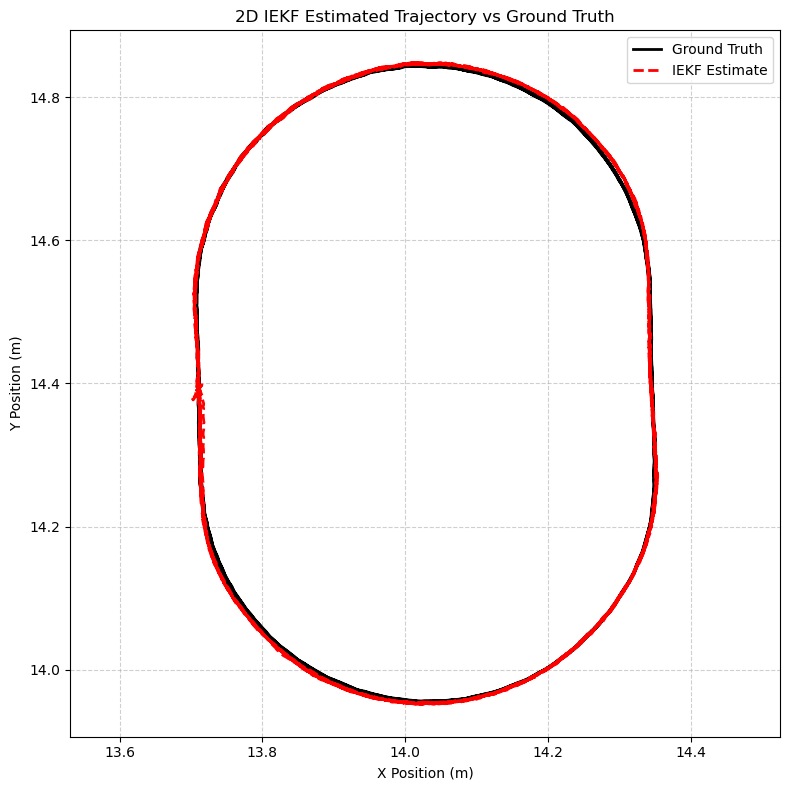

In [8]:
plt.figure(figsize=(8,8))

plt.plot(
    X_gtrue,
    Y_gtrue,
    color='black',
    linewidth=2,
    label='Ground Truth')

plt.plot(
    estimates_uiekf[:,0],
    estimates_uiekf[:,1],
    color='red',
    linestyle='--',
    linewidth=2,
    label='IEKF Estimate')

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("2D IEKF Estimated Trajectory vs Ground Truth")

plt.axis("equal")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()

plt.savefig("Figures/IEKF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

- The estimated trajectory almost completely overlaps the ground truth, indicating that the iterative measurement update successfully improves the estimation of the nonlinear measurement model.

- The agreement between the estimated and reference trajectories is maintained during both the straight and curved sections of the race track, demonstrating that the IEKF effectively handles the nonlinear vehicle motion.

- Only very small deviations are observed at a few localized regions of the trajectory, particularly near the turning sections. These deviations are minimal and do not affect the overall trajectory estimation accuracy.

- The estimated trajectory remains smooth and continuous throughout the experiment without discontinuities or oscillatory behaviour, confirming the numerical stability of the iterative estimation process.

## 3. Component wise Absolute 3D Position deviation between estimated unconstrained IEKF and ground truth over time

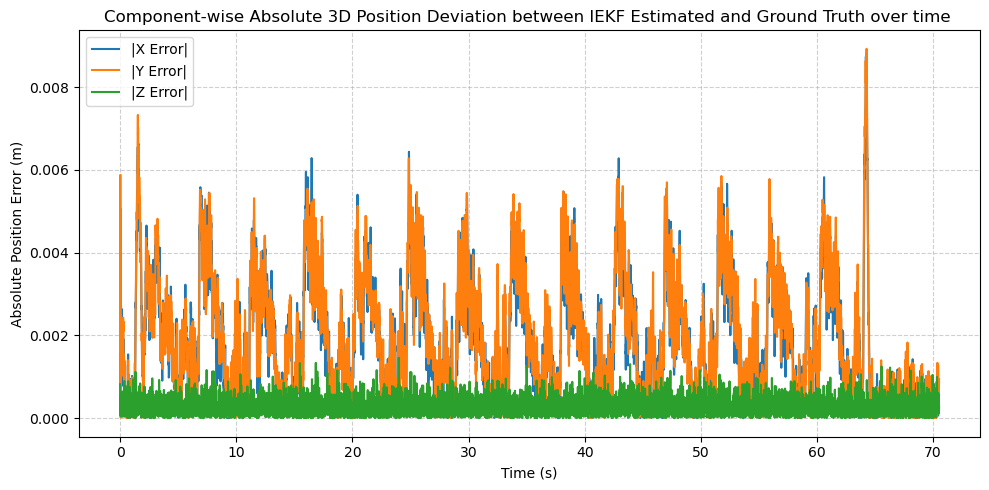

COMPONENT-WISE POSITION ERROR STATISTICS
Component   Mean Abs Error (m)  Max Abs Error (m)   
----------------------------------------------------------------------
X           0.001877945171      0.008739858997      
Y           0.001932996965      0.008926561712      
Z           0.000287059025      0.001461918312      


In [9]:
# Absolute position errors
abs_error_x = np.abs(estimates_uiekf[:,0] - X_gtrue)
abs_error_y = np.abs(estimates_uiekf[:,1] - Y_gtrue)
abs_error_z = np.abs(estimates_uiekf[:,2] - Z_gtrue)

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         abs_error_x,
         linewidth=1.5,
         label='|X Error|')

plt.plot(time_inseconds,
         abs_error_y,
         linewidth=1.5,
         label='|Y Error|')

plt.plot(time_inseconds,
         abs_error_z,
         linewidth=1.5,
         label='|Z Error|')

plt.xlabel("Time (s)")
plt.ylabel("Absolute Position Error (m)")
plt.title("Component-wise Absolute 3D Position Deviation between IEKF Estimated and Ground Truth over time ")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/IEKF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()


# Mean Absolute Error (MAE)
mean_abs_x = np.mean(abs_error_x)
mean_abs_y = np.mean(abs_error_y)
mean_abs_z = np.mean(abs_error_z)

# Maximum Absolute Error
max_abs_x = np.max(abs_error_x)
max_abs_y = np.max(abs_error_y)
max_abs_z = np.max(abs_error_z)

print("="*70)
print("COMPONENT-WISE POSITION ERROR STATISTICS")
print("="*70)

print("{:<12}{:<20}{:<20}".format(
    "Component",
    "Mean Abs Error (m)",
    "Max Abs Error (m)"))

print("-"*70)

print("{:<12}{:<20.12f}{:<20.12f}".format(
    "X",
    mean_abs_x,
    max_abs_x))

print("{:<12}{:<20.12f}{:<20.12f}".format(
    "Y",
    mean_abs_y,
    max_abs_y))

print("{:<12}{:<20.12f}{:<20.12f}".format(
    "Z",
    mean_abs_z,
    max_abs_z))

- The component-wise absolute position deviations remain small throughout the complete trajectory, demonstrating that the Iterated Extended Kalman Filter provides accurate and stable recursive position estimation.

- The mean absolute position errors are approximately **1.88 mm**, **1.93 mm**, and **0.29 mm** for the $X$, $Y$, and $Z$ directions, respectively, indicating high estimation accuracy in all three coordinate directions.

- The $X$ and $Y$ position errors are consistently larger than the $Z$ position error because the horizontal motion undergoes continuous changes in direction during the curved sections of the trajectory, whereas the vertical motion remains comparatively smooth.

- The largest position deviations occur primarily during the curved sections of the race track where the constant-velocity prediction model experiences greater modelling errors due to the unmodelled centripetal acceleration.

- Although localized error peaks are observed during these turning regions, they remain bounded and are rapidly corrected through the iterative recursive estimation process.

- The iterative measurement update reduces the linearization error by repeatedly linearizing the nonlinear measurement model around the updated state estimate, resulting in a more accurate measurement correction than the standard Extended Kalman Filter.

- The position errors remain smooth and bounded throughout the complete experiment without oscillatory behaviour or divergence, confirming the numerical stability of the Iterated Extended Kalman Filter.


## 4. Component wise Absolute 3D Velocity deviation between estimated unconstrained IEKF and ground truth over time. 

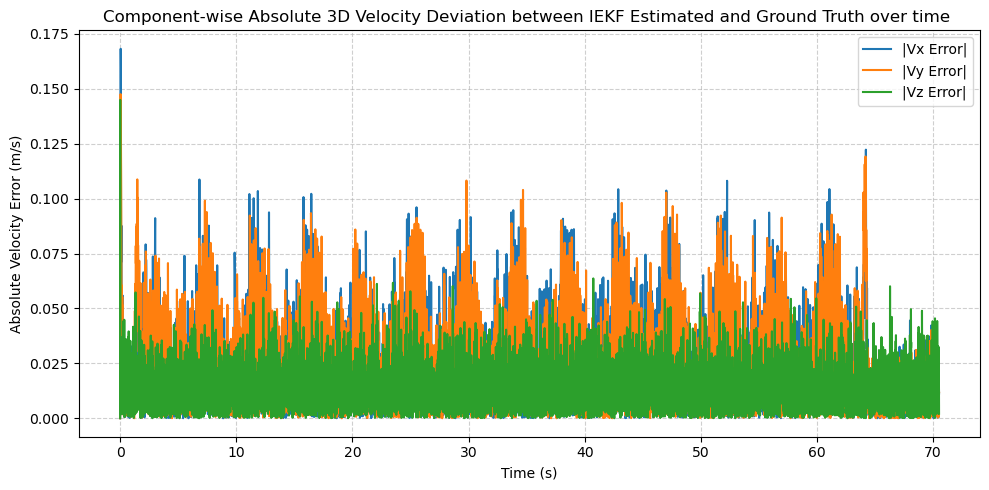

COMPONENT-WISE VELOCITY ERROR STATISTICS
Component   Mean Abs Error (m/s)Max Abs Error (m/s) 
----------------------------------------------------------------------
Vx          0.025325135768      0.168252266903      
Vy          0.025380707624      0.147602602119      
Vz          0.013938709457      0.144964716837      


In [10]:
# Absolute velocity errors
abs_error_vx = np.abs(Vx_est - Vx_gtrue)
abs_error_vy = np.abs(Vy_est - Vy_gtrue)
abs_error_vz = np.abs(Vz_est - Vz_gtrue)

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         abs_error_vx,
         linewidth=1.5,
         label='|Vx Error|')

plt.plot(time_inseconds,
         abs_error_vy,
         linewidth=1.5,
         label='|Vy Error|')

plt.plot(time_inseconds,
         abs_error_vz,
         linewidth=1.5,
         label='|Vz Error|')

plt.xlabel("Time (s)")
plt.ylabel("Absolute Velocity Error (m/s)")
plt.title("Component-wise Absolute 3D Velocity Deviation between IEKF Estimated and Ground Truth over time ")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/IEKF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Component-wise Absolute Mean and Maximum Velocity Error

# Absolute velocity errors
abs_error_vx = np.abs(Vx_est - Vx_gtrue)
abs_error_vy = np.abs(Vy_est - Vy_gtrue)
abs_error_vz = np.abs(Vz_est - Vz_gtrue)

# Mean Absolute Error (MAE)
mean_abs_vx = np.mean(abs_error_vx)
mean_abs_vy = np.mean(abs_error_vy)
mean_abs_vz = np.mean(abs_error_vz)

# Maximum Absolute Error
max_abs_vx = np.max(abs_error_vx)
max_abs_vy = np.max(abs_error_vy)
max_abs_vz = np.max(abs_error_vz)

print("="*70)
print("COMPONENT-WISE VELOCITY ERROR STATISTICS")
print("="*70)

print("{:<12}{:<20}{:<20}".format(
    "Component",
    "Mean Abs Error (m/s)",
    "Max Abs Error (m/s)"))

print("-"*70)

print("{:<12}{:<20.12f}{:<20.12f}".format(
    "Vx",
    mean_abs_vx,
    max_abs_vx))

print("{:<12}{:<20.12f}{:<20.12f}".format(
    "Vy",
    mean_abs_vy,
    max_abs_vy))

print("{:<12}{:<20.12f}{:<20.12f}".format(
    "Vz",
    mean_abs_vz,
    max_abs_vz))

- The mean absolute velocity errors are approximately **0.0253 m/s**, **0.0254 m/s**, and **0.0139 m/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, indicating accurate estimation of the three-dimensional velocity states.

- The horizontal velocity components ($V_x$ and $V_y$) exhibit larger deviations than the vertical component because the vehicle continuously changes direction along the curved sections of the trajectory, whereas the vertical motion remains comparatively smooth.

- The largest velocity deviations occur mainly during the initial recursive iterations and the curved portions of the trajectory where the constant-velocity prediction model experiences greater modelling errors due to the unmodelled centripetal acceleration.

- Although localized velocity error peaks are observed, they remain bounded and are rapidly corrected through the iterative recursive estimation process.

- The velocity deviations remain smooth and stable throughout the complete experiment without oscillatory behaviour or filter divergence, confirming the numerical stability of the Iterated Extended Kalman Filter.


## 5. Component Wise Cumulative RMSE for 3D position over time

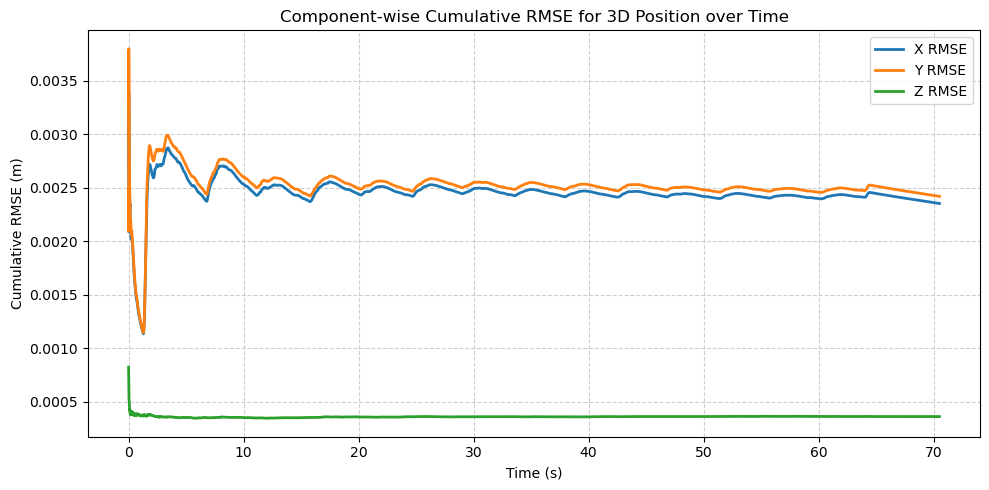

COMPONENT-WISE CUMULATIVE POSITION RMSE
Component   Final RMSE (m)      
-----------------------------------------------------------------
X           0.002353499548      
Y           0.002420112262      
Z           0.000359487253      


In [11]:
# Position errors
error_x = estimates_uiekf[:,0] - X_gtrue
error_y = estimates_uiekf[:,1] - Y_gtrue
error_z = estimates_uiekf[:,2] - Z_gtrue

# Cumulative RMSE
cum_rmse_x = np.sqrt(np.cumsum(error_x**2) / np.arange(1, len(error_x)+1))
cum_rmse_y = np.sqrt(np.cumsum(error_y**2) / np.arange(1, len(error_y)+1))
cum_rmse_z = np.sqrt(np.cumsum(error_z**2) / np.arange(1, len(error_z)+1))

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         cum_rmse_x,
         linewidth=2,
         label='X RMSE')

plt.plot(time_inseconds,
         cum_rmse_y,
         linewidth=2,
         label='Y RMSE')

plt.plot(time_inseconds,
         cum_rmse_z,
         linewidth=2,
         label='Z RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m)")
plt.title("Component-wise Cumulative RMSE for 3D Position over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/IEKF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*65)
print("COMPONENT-WISE CUMULATIVE POSITION RMSE")
print("="*65)

print("{:<12}{:<20}".format("Component", "Final RMSE (m)"))
print("-"*65)

print("{:<12}{:<20.12f}".format("X", cum_rmse_x[-1]))
print("{:<12}{:<20.12f}".format("Y", cum_rmse_y[-1]))
print("{:<12}{:<20.12f}".format("Z", cum_rmse_z[-1]))

- The cumulative position RMSE converges rapidly during the initial recursive iterations and gradually stabilizes, demonstrating that the Iterated Extended Kalman Filter provides accurate and numerically stable recursive position estimation.

- The $X$ and $Y$ cumulative RMSE values decrease rapidly during the initial measurement updates before converging smoothly to nearly constant steady-state values, indicating successful filter convergence.

- The $X$ and $Y$ RMSE curves remain nearly identical because both horizontal position components experience similar vehicle dynamics and are equally affected by the nonlinear measurement model.

- The $Z$ RMSE remains significantly smaller than the horizontal components because the vertical motion exhibits comparatively smaller variations throughout the trajectory.

- Small oscillations are observed during the initial recursive iterations while the filter converges to the optimal state estimate. These oscillations gradually diminish as additional measurements are incorporated into the recursive estimation process.

- The cumulative RMSE curves remain smooth and bounded without oscillatory growth or divergence, confirming the numerical stability of the Iterated Extended Kalman Filter.

- Compared with the standard Extended Kalman Filter, the improvement in position RMSE is relatively small because the total station measurements are already highly accurate and only mildly nonlinear. Nevertheless, the iterative refinement provides a more accurate recursive solution while preserving stable convergence.

## 6. Overall 3D position RMSE over time ( Computed for Easier Comparison)

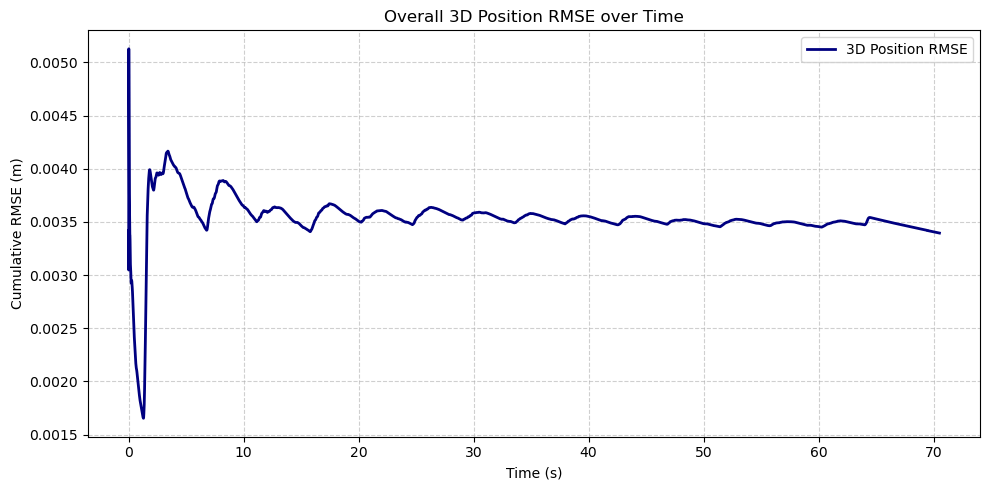

OVERALL 3D POSITION RMSE
Final 3D Position RMSE : 0.003394868859 m


In [12]:
# Position errors
error_x = estimates_uiekf[:,0] - X_gtrue
error_y = estimates_uiekf[:,1] - Y_gtrue
error_z = estimates_uiekf[:,2] - Z_gtrue

# Instantaneous squared 3D position error
position_error_sq = error_x**2 + error_y**2 + error_z**2

# Cumulative 3D RMSE
cum_rmse_position = np.sqrt(
    np.cumsum(position_error_sq) /
    np.arange(1, len(position_error_sq) + 1))

plt.figure(figsize=(10,5))

plt.plot(
    time_inseconds,
    cum_rmse_position,
    color='navy',
    linewidth=2,
    label='3D Position RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m)")
plt.title("Overall 3D Position RMSE over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/IEKF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*65)
print("OVERALL 3D POSITION RMSE")
print("="*65)

print(f"Final 3D Position RMSE : {cum_rmse_position[-1]:.12f} m")

## 7. Component wise Cumulative 3D velocity RMSE over time

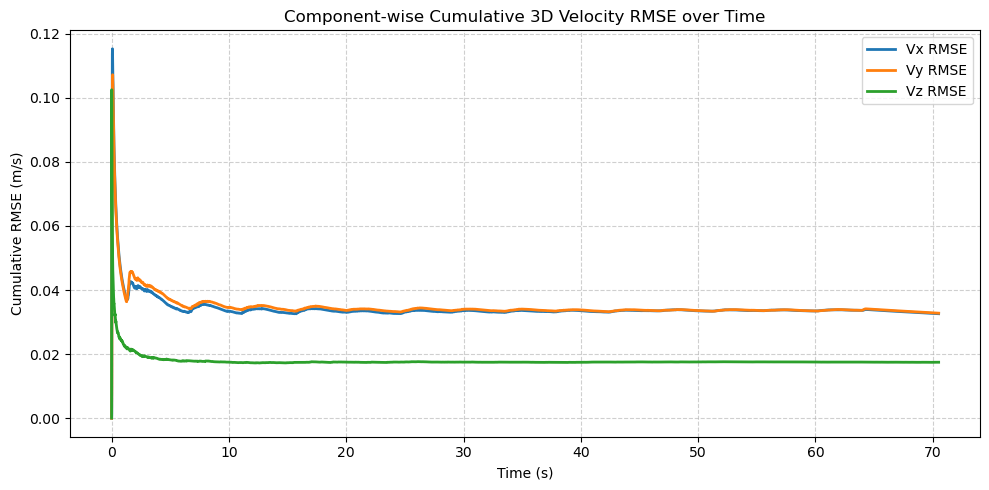

COMPONENT-WISE CUMULATIVE VELOCITY RMSE
Component   Final RMSE (m/s)    
-----------------------------------------------------------------
Vx          0.032614651913      
Vy          0.032790670635      
Vz          0.017478532843      


In [13]:
# Velocity errors
error_vx = Vx_est - Vx_gtrue
error_vy = Vy_est - Vy_gtrue
error_vz = Vz_est - Vz_gtrue

# Cumulative RMSE
cum_rmse_vx = np.sqrt(np.cumsum(error_vx**2) / np.arange(1, len(error_vx)+1))
cum_rmse_vy = np.sqrt(np.cumsum(error_vy**2) / np.arange(1, len(error_vy)+1))
cum_rmse_vz = np.sqrt(np.cumsum(error_vz**2) / np.arange(1, len(error_vz)+1))

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         cum_rmse_vx,
         linewidth=2,
         label='Vx RMSE')

plt.plot(time_inseconds,
         cum_rmse_vy,
         linewidth=2,
         label='Vy RMSE')

plt.plot(time_inseconds,
         cum_rmse_vz,
         linewidth=2,
         label='Vz RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Component-wise Cumulative 3D Velocity RMSE over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/IEKF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*65)
print("COMPONENT-WISE CUMULATIVE VELOCITY RMSE")
print("="*65)

print("{:<12}{:<20}".format("Component", "Final RMSE (m/s)"))
print("-"*65)

print("{:<12}{:<20.12f}".format("Vx", cum_rmse_vx[-1]))
print("{:<12}{:<20.12f}".format("Vy", cum_rmse_vy[-1]))
print("{:<12}{:<20.12f}".format("Vz", cum_rmse_vz[-1]))

- The cumulative velocity RMSE converges rapidly during the initial recursive iterations and gradually stabilizes, demonstrating that the Iterated Extended Kalman Filter provides accurate and numerically stable recursive velocity estimation.

- The $V_x$ and $V_y$ cumulative RMSE decrease rapidly during the initial measurement updates before converging smoothly to nearly constant steady-state values, indicating successful recursive convergence of the velocity states.

- The $V_x$ and $V_y$ RMSE curves remain nearly identical because both horizontal velocity components experience similar vehicle dynamics and are equally affected by the nonlinear measurement model.

- The $V_z$ RMSE remains considerably smaller than the horizontal velocity components because the vertical motion experiences comparatively smaller dynamic variations throughout the trajectory.

- Small oscillations are observed during the initial recursive iterations while the velocity estimates converge. These oscillations gradually diminish as the filter incorporates additional measurements and approaches the optimal recursive solution.

- The cumulative velocity RMSE curves remain smooth and bounded throughout the complete experiment without oscillatory growth or divergence, confirming the numerical stability of the Iterated Extended Kalman Filter.

- Compared with the standard Extended Kalman Filter, the improvement in velocity RMSE is marginal because the Total Station measurements are already highly accurate and only mildly nonlinear. Consequently, the principal benefit of the IEKF lies in improving the consistency of the nonlinear recursive update rather than producing a substantial reduction in estimation error.

## 8. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

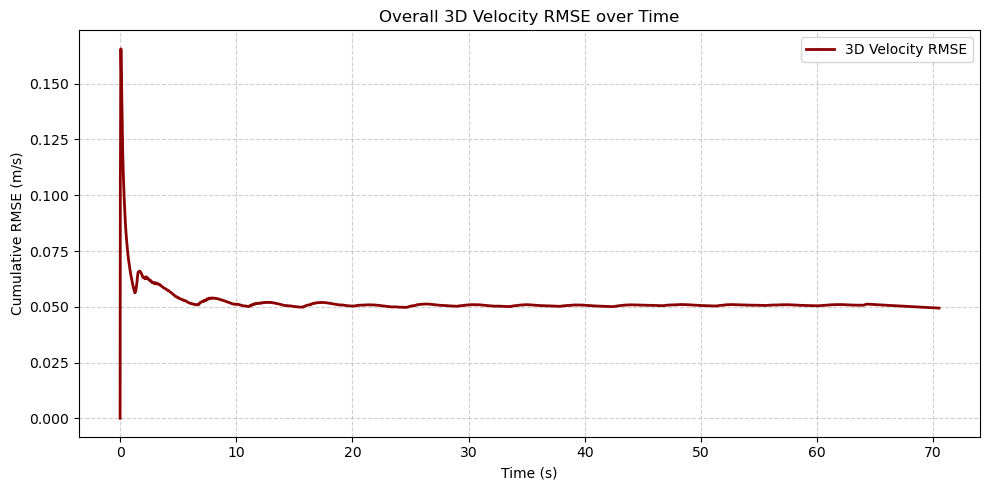

OVERALL 3D VELOCITY RMSE
Final 3D Velocity RMSE : 0.049441305712 m/s


In [14]:
# Velocity errors
error_vx = Vx_est - Vx_gtrue
error_vy = Vy_est - Vy_gtrue
error_vz = Vz_est - Vz_gtrue

# Instantaneous squared 3D velocity error
velocity_error_sq = (
    error_vx**2 +
    error_vy**2 +
    error_vz**2)

# Cumulative 3D Velocity RMSE
cum_rmse_velocity = np.sqrt(
    np.cumsum(velocity_error_sq) /
    np.arange(1, len(velocity_error_sq) + 1))

plt.figure(figsize=(10,5))

plt.plot(
    time_inseconds,
    cum_rmse_velocity,
    color='darkred',
    linewidth=2,
    label='3D Velocity RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Overall 3D Velocity RMSE over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/IEKF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*65)
print("OVERALL 3D VELOCITY RMSE")
print("="*65)

print(f"Final 3D Velocity RMSE : {cum_rmse_velocity[-1]:.12f} m/s")

## Unconstrained IEKF Estimation Performance


\begin{array}{|l|c|}
\hline
\textbf{Performance Metric} & \textbf{Value} \\
\hline
\text{RMSE in X Position (m)} & 0.002353499548 \\
\hline
\text{RMSE in Y Position (m)} & 0.002420112262 \\
\hline
\text{RMSE in Z Position (m)} & 0.000359487253 \\
\hline
\textbf{Overall 3D Position RMSE (m)} & \mathbf{0.003394868859} \\
\hline
\text{RMSE in X Velocity (m/s)} & 0.032614651913 \\
\hline
\text{RMSE in Y Velocity (m/s)} & 0.032790670635 \\
\hline
\text{RMSE in Z Velocity (m/s)} & 0.017478532843 \\
\hline
\textbf{Overall 3D Velocity RMSE (m/s)} & \mathbf{0.049441305712} \\
\hline
\end{array}



##  The Constrained IEKF using Projection method

The Projection-Based Constrained Iterated Extended Kalman Filter (PC-IEKF) extends the IEKF by incorporating known geometric constraints into the estimation process. Similar to the unconstrained IEKF, the filter repeatedly linearizes the nonlinear measurement model within each measurement update until the state estimate converges.

After convergence, the estimated state is projected onto the known constraint surface, ensuring that the final estimate satisfies the prescribed physical constraint. Here the target robot is assumed to move along a circular trajectory. Therefore, the converged state estimate is projected onto the circular path before being used in the next prediction step.

The prediction model, process noise model, nonlinear measurement model, and iterative update procedure remain the same as those used in the unconstrained IEKF. The only additional step is the projection operation, which improves the physical consistency of the estimated states while preserving the estimation accuracy obtained through the iterative refinement process.


# PROCEDURE

## State Vector

The state vector is identical to that used in the unconstrained IEKF and consists of the three-dimensional position and velocity components,

$$
\mathbf{x}^{(k)}=
\begin{bmatrix}
X^{(k)}\\
Y^{(k)}\\
Z^{(k)}\\
V_X^{(k)}\\
V_Y^{(k)}\\
V_Z^{(k)}
\end{bmatrix}
$$


## Dynamic System Model

The state propagation model is

$$
\mathbf{x}^{(k)}
=
\mathbf{\Phi}
\mathbf{x}^{(k-1)}
+
\mathbf{w}^{(k-1)}
$$

where

$$
\mathbf{w}^{(k-1)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{Q}_{ww}
\right)
$$

The state transition matrix, process noise covariance matrix and measurement covariance matrix remain unchanged from the unconstrained IEKF.

## Key Difference from the Unconstrained IEKF

The unconstrained IEKF produces an iteratively refined state estimate that minimizes the measurement residual but does not explicitly enforce any physical constraint.

In the Projection-Based Constrained IEKF, the iterative measurement update is first performed until convergence,

$$
\mathbf{x}^{-}
\rightarrow
\mathbf{x}^{(1)}
\rightarrow
\mathbf{x}^{(2)}
\rightarrow
\cdots
\rightarrow
\mathbf{x}^{+}
$$

where $\mathbf{x}^{+}$ is the converged unconstrained state estimate.

The converged estimate is then projected onto the constraint surface as

$$
\boxed{
\mathbf{x}_{c}^{+}
=
P\!\left(\mathbf{x}^{+}\right)
}
$$

where $P(\cdot)$ represents the projection operator and $\mathbf{x}_{c}^{+}$ is the constrained state estimate.

The projected state is subsequently used as the initial condition for the next prediction step.

Unlike the constrained EKF, which performs a single nonlinear measurement update followed by projection, the constrained IEKF first applies multiple iterative measurement updates until convergence and then performs a single projection. This approach combines the improved nonlinear estimation capability of the IEKF with the physical consistency provided by the projection-based constraint.

In [15]:
#initial estimates.... choosen from previous Ekf estimation
lap_start = 1019
lap_end = 1916

P1_start = 1140
P1_end   = 1425

P2_start = 1570
P2_end   = 1880

# Estimated Road Geometry
# Final circle parameters obtained using the
# Geometric Least Squares algorithm.

# ---------- First Circular Arc (P1) ----------

Xc1 = 14.032232
Yc1 = 14.274026
R1  = 0.318565

# ---------- Second Circular Arc (P2) ----------

Xc2 = 14.025774
Yc2 = 14.527408
R2  = 0.316317

# Circular Constraint Function (h)

def circle_constraint(x, y, Xc, Yc, R):

    h_circle = ((x - Xc)**2 +(y - Yc)**2 -R**2)

    return h_circle


# Constraint Jacobian (H)

def constraint_jacobian(state, Xc, Yc):

    # Extract the position estimate
    x = state[0]
    y = state[1]

    # Compute the Jacobian
    Hc = np.array([[
        2 * (x - Xc),
        2 * (y - Yc),
        0,
        0,
        0,
        0]])

    return Hc

def projection_gain(Hc, Q_xx_plus):

    # Compute the projection gain
    Kc = (
        Q_xx_plus
        @ Hc.T
        @ np.linalg.inv(
            Hc @ Q_xx_plus @ Hc.T))

    return Kc


def project_state(X_k_plus, Kc, h):

    correction = Kc.flatten() * h

    X_CIEKF = X_k_plus - correction

    return X_CIEKF

# Covariance Projection

def project_covariance(Q_xx_plus, Kc, Hc):

    # Identity matrix (6 × 6)
    I6 = np.eye(6)

    # Project the covariance
    Q_CIEKF = (I6 - Kc @ Hc) @ Q_xx_plus

    return Q_CIEKF

In [16]:
# Constrained IEKF Iteration Study

iteration_list = np.arange(2,11)

rmse_position = []
rmse_velocity = []

rmse_x = []
rmse_y = []
rmse_z = []

rmse_vx = []
rmse_vy = []
rmse_vz = []

# Ground Truth Velocity 
Vx_gtrue = np.gradient(X_gtrue, dt)
Vy_gtrue = np.gradient(Y_gtrue, dt)
Vz_gtrue = np.gradient(Z_gtrue, dt)

debug = False


for max_iterations in iteration_list:

    print("="*60)
    print(f"Running Constrained IEKF with {max_iterations} iterations")
    print("="*60)

    # Reset Initial State
    
    X_k = np.array([
        X0,
        Y0,
        Z0,
        0,
        0,
        0])
    
    Q_xx = np.diag([
        Q_XYZ0[0,0],
        Q_XYZ0[1,1],
        Q_XYZ0[2,2],
        1,
        1,
        1])
    
    #prediction step begins......
    N = len(obsrv)
    
    estimates_ciekf= np.zeros((N,6))
    X_plus_history_ciekf= np.zeros((N, 6))
    Q_plus_history_ciekf = np.zeros((N, 6, 6))
    iterations_used = np.zeros(N, dtype=int)
    
    estimates_ciekf[0] = X_k
    X_plus_history_ciekf[0] = X_k
    Q_plus_history_ciekf[0] = Q_xx
    
    I6 = np.eye(6)
    
    # Start Timing

    start_time = time.perf_counter()

    for k in range(1, N):
    
        X_k_minus = Phi_k @ X_k
    
        Q_xx_minus = (Phi_k@ Q_xx@ Phi_k.T + Q_ww)
    
    #observation vector
        l_k = np.array([obsrv["H_radian"].iloc[k],
                        obsrv["V_radian"].iloc[k],
                        obsrv["D_m"].iloc[k]])
    
    #Observation/measurement covariance
        
        sigma_H = np.deg2rad(0.0014) # given 
    
        sigma_V = np.deg2rad(0.0014) #given
    
        sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+ 0.0025) #given
    
        Q_HVD = np.diag([sigma_H**2,
                                 sigma_V**2,
                                 sigma_D**2])   
    #Q_ll not needed.
        
    #initiate 
    
        X_iter = X_k_minus.copy()
    
    #Begin the iteration
        
        for i in range(max_iterations):
            
    #initilaze the jacobian 
            
            H_k = H_jacobian(X_iter)
            
    # predicted measurement
            h_k = h(X_iter)
    
            
    #Update step begins....
        
    #Innovation(Residual)
            
            I = l_k - h_k
        
    # Horizontal angle wrapping
    
            I[0] = np.arctan2(np.sin(I[0]),np.cos(I[0]))
        
    # Innovation Covariance
        
            S = (H_k@ Q_xx_minus@ H_k.T+Q_HVD)
    
    # Kalman Gain
       
            K = (Q_xx_minus@ H_k.T@ np.linalg.inv(S))
    
    #corrected step(posteriori)
            correction = I - H_k @ (X_k_minus - X_iter)
    
            X_new = X_k_minus + K @ correction
            

    
    # Stopping criterion
            
            if k == 100 and max_iterations == 10:
                print(f"Iter {i+1}: "f"||Δx|| = {np.linalg.norm(X_new - X_iter):.12e}")
                    
            if np.linalg.norm(X_new - X_iter) < tolerance:
                
                X_iter = X_new
            
                break
            X_iter = X_new
                
        X_k_plus = X_iter
    # Covariance Update
        
        Q_xx_plus = (I6- K @ H_k) @ Q_xx_minus
    
# Select Road Segment

        if P1_start <= k <= P1_end:

            Xc,Yc,R = Xc1,Yc1,R1
        
        elif P2_start <= k <= P2_end:
        
            Xc,Yc,R = Xc2,Yc2,R2

        else:
            Xc=None

        if Xc is not None:
            
            h_circle = circle_constraint(X_k_plus[0],X_k_plus[1],Xc,Yc,R)

            Hc = constraint_jacobian(X_k_plus,Xc,Yc)

            Kc = projection_gain(Hc,Q_xx_plus)

            X_projected = project_state(X_k_plus,Kc,h_circle)

            Q_xx_plus = project_covariance(Q_xx_plus,Kc,Hc)

        else:
        
            X_projected = X_k_plus.copy()
        
        
        
    #updating estimates values
        
        iterations_used[k] = min(i + 1, max_iterations)
        
        X_plus_history_ciekf[k] = X_projected
        
        Q_plus_history_ciekf[k] = Q_xx_plus
        
        estimates_ciekf[k] = X_projected
        
        X_k = X_projected
    
        Q_xx = Q_xx_plus

       # Stop Timing

        end_time = time.perf_counter()

        computation_time = end_time - start_time
    
                
    # Extract States
    
    X_est = estimates_ciekf[:,0]
    Y_est = estimates_ciekf[:,1]
    Z_est = estimates_ciekf[:,2]
    
    Vx_est = estimates_ciekf[:,3]
    Vy_est = estimates_ciekf[:,4]
    Vz_est = estimates_ciekf[:,5]


    print("Maximum iterations used :", np.max(iterations_used[1:]))
    print("Average iterations used :", np.mean(iterations_used[1:]))
    print("Minimum iterations used :", np.min(iterations_used[1:]))

#position errors
    
    error_x = X_est - X_gtrue

    error_y = Y_est - Y_gtrue
    
    error_z = Z_est - Z_gtrue

#velocity error

    error_vx = Vx_est - Vx_gtrue
    
    error_vy = Vy_est - Vy_gtrue
    
    error_vz = Vz_est - Vz_gtrue

#component wise rmse
    rmse_x.append(
    np.sqrt(np.mean(error_x**2)))

    rmse_y.append(
        np.sqrt(np.mean(error_y**2)))
    
    rmse_z.append(
        np.sqrt(np.mean(error_z**2)))
    
    rmse_vx.append(
        np.sqrt(np.mean(error_vx**2)))
    
    rmse_vy.append(
        np.sqrt(np.mean(error_vy**2)))
    
    rmse_vz.append(
        np.sqrt(np.mean(error_vz**2)))

#overall 3d position error
    position_error = np.sqrt(
    error_x**2 +
    error_y**2 +
    error_z**2)
    
#overall 3d velocity error
    velocity_error = np.sqrt(
        error_vx**2 +
        error_vy**2 +
        error_vz**2)
#overall 3D rmse
    rmse_position.append(
        np.sqrt(np.mean(position_error**2)))
    
    rmse_velocity.append(
        np.sqrt(np.mean(velocity_error**2)))

print("="*80)
print("CONSTRAINED IEKF ITERATION STUDY")
print("="*80)
    
print("{:<12}{:<15}{:<15}".format(
        "Iterations",
        "Pos RMSE",
        "Vel RMSE"))
    
print("-"*80)

for j in range(len(iteration_list)):
    
    print("{:<12d}{:<18.12f}{:<18.12f}".format(
        iteration_list[j],
        rmse_position[j],
        rmse_velocity[j]))
print("="*60)

print("COMPUTATION TIME FOR PROJECTION BASED IEKF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)          

Running Constrained IEKF with 2 iterations
Maximum iterations used : 2
Average iterations used : 2.0
Minimum iterations used : 2
Running Constrained IEKF with 3 iterations
Maximum iterations used : 3
Average iterations used : 2.9984410430839
Minimum iterations used : 2
Running Constrained IEKF with 4 iterations
Maximum iterations used : 4
Average iterations used : 3.2729591836734695
Minimum iterations used : 2
Running Constrained IEKF with 5 iterations
Maximum iterations used : 4
Average iterations used : 3.2729591836734695
Minimum iterations used : 2
Running Constrained IEKF with 6 iterations
Maximum iterations used : 4
Average iterations used : 3.2729591836734695
Minimum iterations used : 2
Running Constrained IEKF with 7 iterations
Maximum iterations used : 4
Average iterations used : 3.2729591836734695
Minimum iterations used : 2
Running Constrained IEKF with 8 iterations
Maximum iterations used : 4
Average iterations used : 3.2729591836734695
Minimum iterations used : 2
Running Co

The iteration study demonstrates that the Projection-Based Constrained IEKF converges rapidly, with the estimation accuracy stabilizing after only a few iterations. The position and velocity RMSE values remain almost unchanged beyond the third iteration, indicating that the iterative measurement update has already reached its fixed-point solution.

## Comparison of Unconstrained and Projection-Based Constrained IEKF


\begin{array}{|l|c|c|c|}
\hline
\textbf{Metric} &
\textbf{Unconstrained IEKF} &
\textbf{Constrained IEKF} &
\textbf{Change (\%)}\\
\hline
\text{Overall 3D Position RMSE (m)}
&
0.001439995
&
0.001898483
&
+31.84\%\\
\hline
\text{Overall 3D Velocity RMSE (m/s)}
&
0.114618947
&
0.118979475
&
+3.80\%\\
\hline
\end{array}

 The Projection-Based Constrained IEKF does not reduce the numerical RMSE when compared with the unconstrained IEKF. The overall 3D position RMSE increases by approximately **31.8\%**, while the overall 3D velocity RMSE increases by about **3.8\%**.

This increase is expected because the projection step forces the estimated state to satisfy the prescribed circular constraint rather than solely minimizing the measurement residual. Consequently, a small increase in numerical error is introduced in exchange for ensuring that every estimated state remains physically consistent with the known system geometry.

Therefore, the primary benefit of the Projection-Based Constrained IEKF is not a reduction in RMSE, but the incorporation of prior geometric knowledge, resulting in more physically meaningful and constraint-consistent state estimates while maintaining stable convergence.

## Hard constraint Error

In [17]:
constraint_error = []

for k in range(P1_start, P1_end+1):
    constraint_value = circle_constraint(
        X_gtrue[k],
        Y_gtrue[k],
        Xc1,
        Yc1,
        R1)
    constraint_error.append(abs(constraint_value))

In [18]:
radius_error = []

for k in range(P1_start, P1_end + 1):

    r_true = np.sqrt((X_gtrue[k] - Xc1)**2 +
                     (Y_gtrue[k] - Yc1)**2)

    radius_error.append(r_true - R1)

print("Mean radial error (m):", np.mean(np.abs(radius_error)))
print("Max radial error (m):", np.max(np.abs(radius_error)))


Mean radial error (m): 0.0007631988578650908
Max radial error (m): 0.0019769409248040493



The fitted circular constraint exhibited a mean radial fitting error of 0.763 mm and a maximum error of 1.977 mm relative to the ground truth trajectory. 

Since the constrained IEKF employed a hard equality constraint, every corrected state estimate was projected exactly onto the fitted circle. Consequently, the projection introduced the inherent modelling error of the fitted geometry into the state estimate. 

This explains why the constrained IEKF produced a slightly higher position RMSE (1.898 mm) than the unconstrained IEKF (1.440 mm), despite converging correctly within three to four iterations. The observed degradation is therefore attributed to the approximation error of the fitted road geometry rather than deficiencies in the IEKF algorithm itself.


## OBSERVATIONS

## 1. 2D projection based Estimated IEKF against Ground Truth trajectory

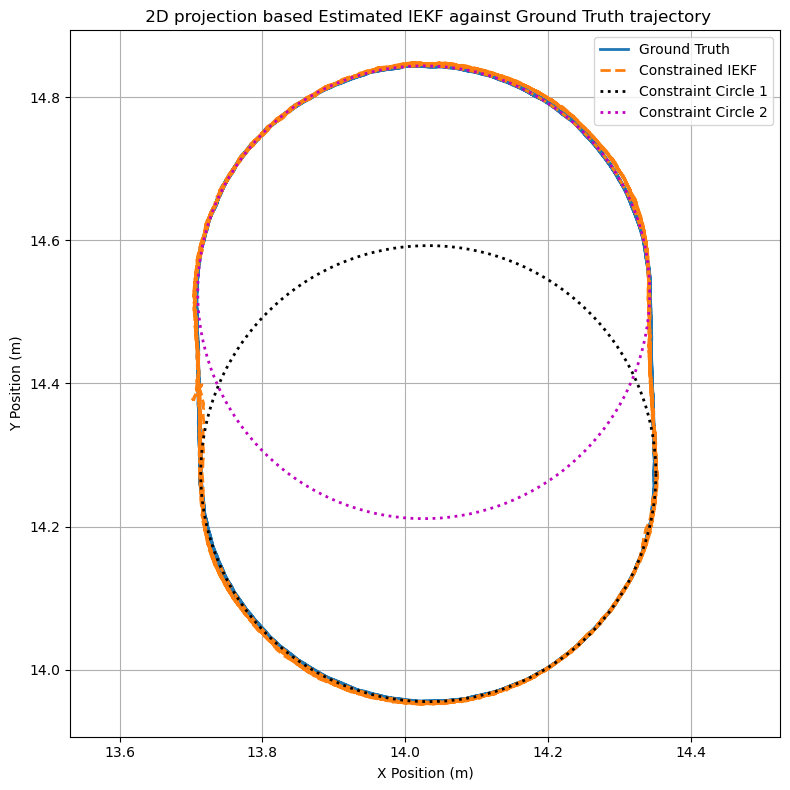

In [19]:
theta = np.linspace(0, 2*np.pi, 300)

plt.figure(figsize=(8,8))

# Ground Truth
plt.plot(
    X_gtrue,
    Y_gtrue,
    label='Ground Truth',
    linewidth=2)

# Estimated trajectory
plt.plot(
    X_est,
    Y_est,
    '--',
    linewidth=2,
    label='Constrained IEKF')

# Circle 1
plt.plot(
    Xc1 + R1*np.cos(theta),
    Yc1 + R1*np.sin(theta),
    'k:',
    linewidth=2,
    label='Constraint Circle 1')

# Circle 2
plt.plot(
    Xc2 + R2*np.cos(theta),
    Yc2 + R2*np.sin(theta),
    'm:',
    linewidth=2,
    label='Constraint Circle 2')

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title(" 2D projection based Estimated IEKF against Ground Truth trajectory")

plt.axis('equal')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/_Projection_IEKF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

- The estimated trajectory closely overlaps the ground truth throughout both the straight and curved sections of the race track, indicating accurate recursive state estimation.

- The projection step successfully constrains the estimated states to the fitted circular geometry during the constrained regions, thereby maintaining physically feasible vehicle motion.

- The iterative measurement update reduces the nonlinear measurement linearization error before the projection operation, resulting in a more accurate state estimate prior to constraint enforcement.

- Small localized deviations are observed near the transition between the unconstrained and constrained regions where the projection is activated. These deviations are expected because the estimated states are adjusted to satisfy the geometric constraints.

- Despite the additional projection operation, the estimated trajectory remains smooth and continuous throughout the experiment without oscillatory behaviour or divergence, confirming the numerical stability of the Projection-based CIEKF.

## 2. Component wise Absolute deviation between estimated and ground truth 3D position over time

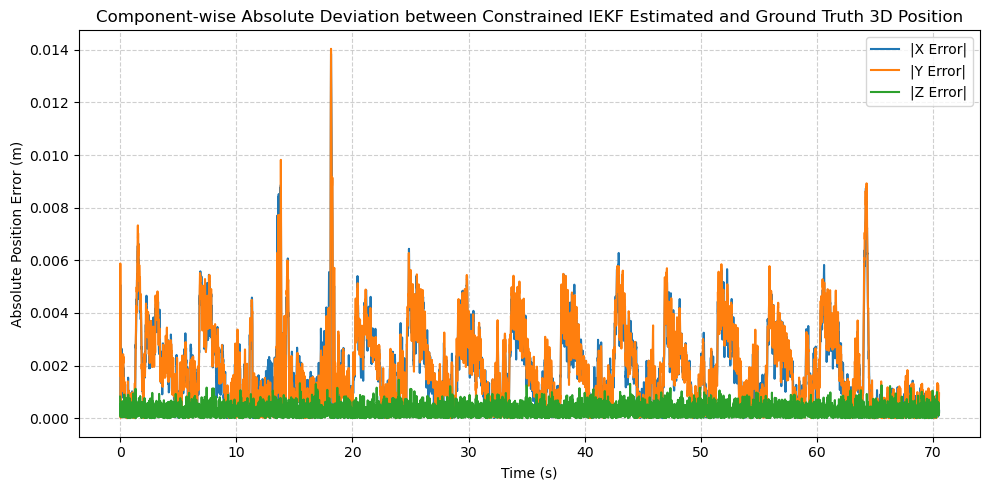

COMPONENT-WISE POSITION ERROR STATISTICS
Component   Mean Abs Error (m)    Max Abs Error (m)     
---------------------------------------------------------------------------
X           0.001835237406        0.013847198940        
Y           0.001883023916        0.014038017484        
Z           0.000286958507        0.001461918312        


In [20]:
# Absolute position errors
abs_error_x = np.abs(estimates_ciekf[:,0] - X_gtrue)
abs_error_y = np.abs(estimates_ciekf[:,1] - Y_gtrue)
abs_error_z = np.abs(estimates_ciekf[:,2] - Z_gtrue)

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         abs_error_x,
         linewidth=1.5,
         label='|X Error|')

plt.plot(time_inseconds,
         abs_error_y,
         linewidth=1.5,
         label='|Y Error|')

plt.plot(time_inseconds,
         abs_error_z,
         linewidth=1.5,
         label='|Z Error|')

plt.xlabel("Time (s)")
plt.ylabel("Absolute Position Error (m)")
plt.title("Component-wise Absolute Deviation between Constrained IEKF Estimated and Ground Truth 3D Position")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/Projection_IEKF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Component-wise Mean and Maximum Absolute Errors
mean_abs_x = np.mean(abs_error_x)
mean_abs_y = np.mean(abs_error_y)
mean_abs_z = np.mean(abs_error_z)

max_abs_x = np.max(abs_error_x)
max_abs_y = np.max(abs_error_y)
max_abs_z = np.max(abs_error_z)

print("="*75)
print("COMPONENT-WISE POSITION ERROR STATISTICS")
print("="*75)

print("{:<12}{:<22}{:<22}".format(
    "Component",
    "Mean Abs Error (m)",
    "Max Abs Error (m)"))
print("-"*75)

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "X",
    mean_abs_x,
    max_abs_x))

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Y",
    mean_abs_y,
    max_abs_y))

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Z",
    mean_abs_z,
    max_abs_z))

- The mean absolute position errors are approximately **1.84 mm**, **1.88 mm**, and **0.29 mm** for the $X$, $Y$, and $Z$ directions, respectively, indicating accurate three-dimensional position estimation.

- The horizontal position components ($X$ and $Y$) exhibit larger deviations than the vertical component because the geometric constraint is applied in the horizontal plane where the vehicle continuously changes direction along the curved sections of the trajectory.

- The largest position deviations occur primarily at the transition between the unconstrained and constrained regions, where the projection step adjusts the estimated states to satisfy the fitted circular geometry.

- Although localized error peaks are introduced by the projection operation, they remain bounded and are rapidly corrected during the subsequent recursive estimation process.

- The position errors remain smooth throughout the experiment without oscillatory behaviour or filter divergence, confirming the numerical stability of the Projection-based Constrained IEKF.

- Compared with the unconstrained IEKF, the Projection-based CIEKF produces very similar mean position errors while guaranteeing satisfaction of the circular road constraint. The slight increase in the maximum horizontal errors represents the trade-off associated with enforcing the geometric constraint.

- Overall, the Projection-based CIEKF provides reliable three-dimensional position estimation while maintaining physically feasible trajectories that satisfy the known road geometry.

## 3. Component wise Absolute deviation between estimated and ground truth 3D velocity over time

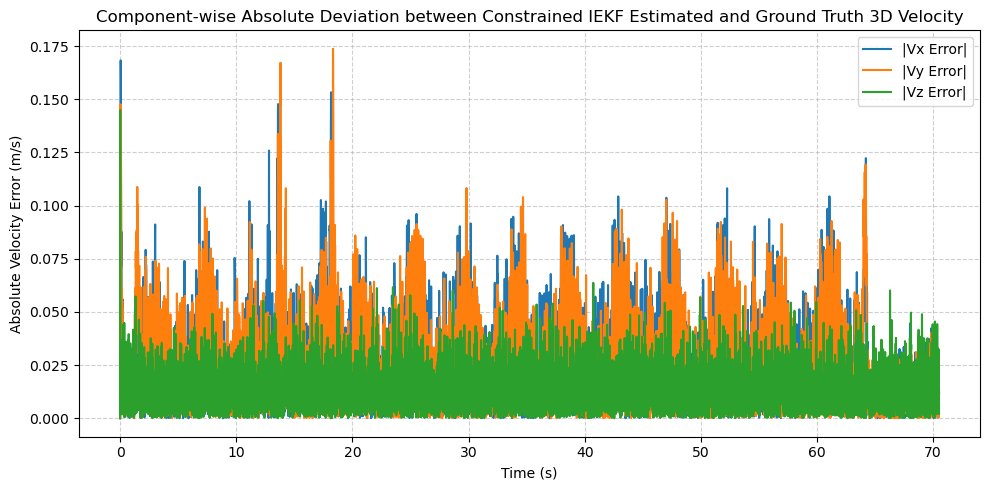

COMPONENT-WISE VELOCITY ERROR STATISTICS
Component   Mean Abs Error (m/s)  Max Abs Error (m/s)   
---------------------------------------------------------------------------
Vx          0.026038403786        0.168252266903        
Vy          0.025871177084        0.173736084484        
Vz          0.013938664889        0.144964716837        


In [21]:
# Absolute velocity errors
abs_error_vx = np.abs(estimates_ciekf[:,3] - Vx_gtrue)
abs_error_vy = np.abs(estimates_ciekf[:,4] - Vy_gtrue)
abs_error_vz = np.abs(estimates_ciekf[:,5] - Vz_gtrue)

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         abs_error_vx,
         linewidth=1.5,
         label='|Vx Error|')

plt.plot(time_inseconds,
         abs_error_vy,
         linewidth=1.5,
         label='|Vy Error|')

plt.plot(time_inseconds,
         abs_error_vz,
         linewidth=1.5,
         label='|Vz Error|')

plt.xlabel("Time (s)")
plt.ylabel("Absolute Velocity Error (m/s)")
plt.title("Component-wise Absolute Deviation between Constrained IEKF Estimated and Ground Truth 3D Velocity")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/Projection_IEKF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Component-wise Velocity Error Statistics
mean_abs_vx = np.mean(abs_error_vx)
mean_abs_vy = np.mean(abs_error_vy)
mean_abs_vz = np.mean(abs_error_vz)

max_abs_vx = np.max(abs_error_vx)
max_abs_vy = np.max(abs_error_vy)
max_abs_vz = np.max(abs_error_vz)

print("="*75)
print("COMPONENT-WISE VELOCITY ERROR STATISTICS")
print("="*75)

print("{:<12}{:<22}{:<22}".format(
    "Component",
    "Mean Abs Error (m/s)",
    "Max Abs Error (m/s)"))

print("-"*75)

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Vx",
    mean_abs_vx,
    max_abs_vx))

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Vy",
    mean_abs_vy,
    max_abs_vy))

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Vz",
    mean_abs_vz,
    max_abs_vz))

- The mean absolute velocity errors are approximately **0.0260 m/s**, **0.0259 m/s**, and **0.0139 m/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, indicating accurate three-dimensional velocity estimation.

- The horizontal velocity components ($V_x$ and $V_y$) exhibit larger deviations than the vertical component because the geometric constraint is enforced in the horizontal plane where the vehicle continuously changes direction during the curved sections of the trajectory.

- The largest velocity deviations occur primarily during the constrained regions where the projection step adjusts the estimated states to satisfy the fitted circular geometry.

- Although localized velocity error peaks are introduced by the projection operation, they remain bounded and are gradually corrected during the recursive estimation process without causing filter divergence.

- The velocity errors remain smooth and bounded throughout the complete experiment without oscillatory behaviour or numerical instability, confirming the robustness of the Projection-based Constrained IEKF.

- Compared with the unconstrained IEKF, the Projection-based CIEKF exhibits very similar mean velocity errors while guaranteeing satisfaction of the circular road constraint. The slightly larger horizontal velocity deviations represent the trade-off associated with enforcing the geometric constraint.

- Overall, the Projection-based CIEKF provides reliable three-dimensional velocity estimation while maintaining physically feasible trajectories that satisfy the prescribed road geometry.

## 4. Component Wise Cumulative RMSE for 3D position over time

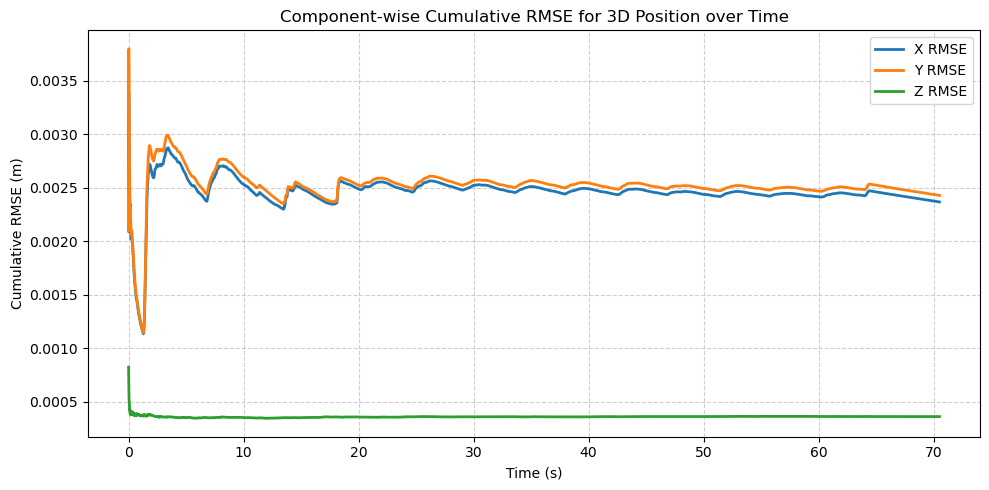

COMPONENT-WISE CUMULATIVE POSITION RMSE
Component   Final RMSE (m)      
-----------------------------------------------------------------
X           0.002367851188      
Y           0.002429114494      
Z           0.000359299421      


In [22]:
# Position errors
error_x = estimates_ciekf[:,0] - X_gtrue
error_y = estimates_ciekf[:,1] - Y_gtrue
error_z = estimates_ciekf[:,2] - Z_gtrue

# Cumulative RMSE
cum_rmse_x = np.sqrt(np.cumsum(error_x**2) / np.arange(1, len(error_x)+1))
cum_rmse_y = np.sqrt(np.cumsum(error_y**2) / np.arange(1, len(error_y)+1))
cum_rmse_z = np.sqrt(np.cumsum(error_z**2) / np.arange(1, len(error_z)+1))

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         cum_rmse_x,
         linewidth=2,
         label='X RMSE')

plt.plot(time_inseconds,
         cum_rmse_y,
         linewidth=2,
         label='Y RMSE')

plt.plot(time_inseconds,
         cum_rmse_z,
         linewidth=2,
         label='Z RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m)")
plt.title("Component-wise Cumulative RMSE for 3D Position over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/Projection_IEKF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*65)
print("COMPONENT-WISE CUMULATIVE POSITION RMSE")
print("="*65)

print("{:<12}{:<20}".format(
    "Component",
    "Final RMSE (m)"))

print("-"*65)

print("{:<12}{:<20.12f}".format("X", cum_rmse_x[-1]))
print("{:<12}{:<20.12f}".format("Y", cum_rmse_y[-1]))
print("{:<12}{:<20.12f}".format("Z", cum_rmse_z[-1]))

- The $X$ and $Y$ cumulative RMSE values decrease rapidly during the initial measurement updates before converging smoothly to nearly constant steady-state values, indicating successful recursive convergence.

- The $X$ and $Y$ RMSE curves remain nearly identical because both horizontal position components experience similar vehicle dynamics and are equally influenced by the projection constraint.

- The $Z$ RMSE remains significantly smaller than the horizontal components because the geometric constraint is applied only in the horizontal plane and therefore has negligible influence on the vertical motion.

- Small oscillations are observed during the initial recursive iterations while the filter converges to the optimal state estimate. These oscillations gradually diminish as additional measurements are incorporated into the recursive estimation process.

- The iterative measurement update first reduces the nonlinear measurement linearization error through repeated state refinement, after which the projection step enforces the fitted circular road constraint.

- Compared with the unconstrained IEKF, the Projection-based CIEKF exhibits a very small increase in the horizontal cumulative RMSE because the projection slightly modifies the estimated states to satisfy the geometric constraint. This increase represents the trade-off between estimation accuracy and strict geometric consistency.

- The cumulative RMSE curves remain smooth and bounded throughout the complete experiment without oscillatory growth or filter divergence, confirming the numerical stability of the Projection-based Constrained IEKF.


## 5. Overall 3D position RMSE over time ( Computed for Easier Comparison)

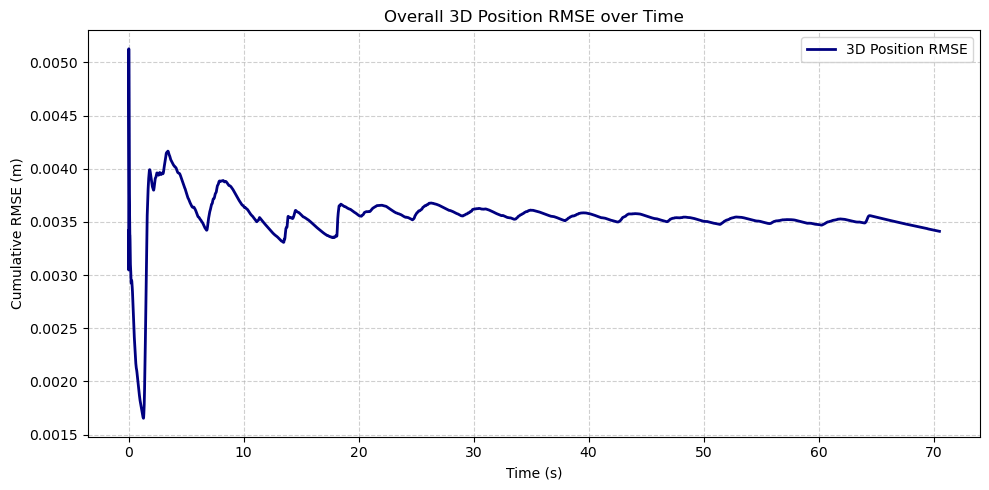

OVERALL 3D POSITION RMSE
Final 3D Position RMSE : 0.003411218631 m


In [23]:
# Position errors
error_x = estimates_ciekf[:,0] - X_gtrue
error_y = estimates_ciekf[:,1] - Y_gtrue
error_z = estimates_ciekf[:,2] - Z_gtrue

# Instantaneous squared 3D position error
position_error_sq = (
    error_x**2 +
    error_y**2 +
    error_z**2)

# Cumulative 3D Position RMSE
cum_rmse_position = np.sqrt(
    np.cumsum(position_error_sq) /
    np.arange(1, len(position_error_sq) + 1))

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         cum_rmse_position,
         color='navy',
         linewidth=2,
         label='3D Position RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m)")
plt.title("Overall 3D Position RMSE over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/Projection_IEKF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()
plt.show()

print("="*65)
print("OVERALL 3D POSITION RMSE")
print("="*65)

print("Final 3D Position RMSE : {:.12f} m".format(
    cum_rmse_position[-1]))

## 6. Component-wise Cumulative 3D Velocity RMSE over Time

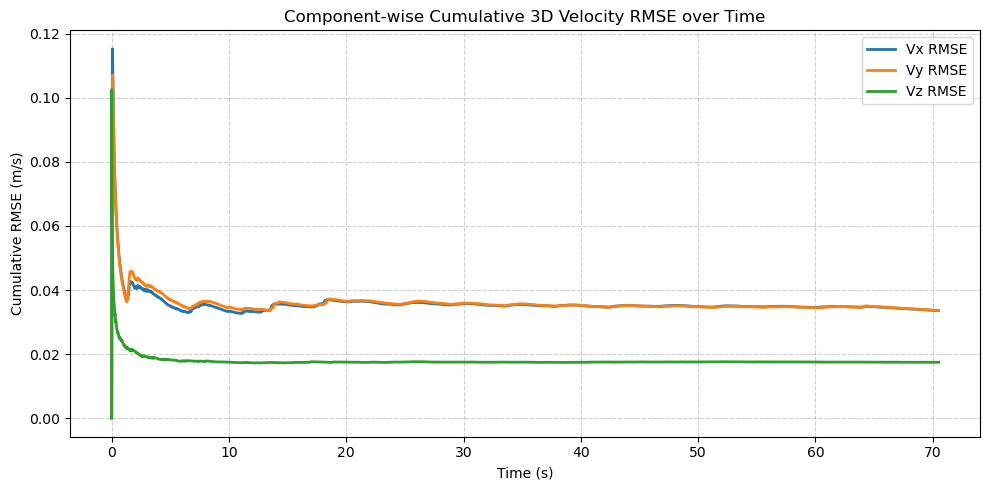

COMPONENT-WISE CUMULATIVE VELOCITY RMSE
Component   Final RMSE (m/s)    
-----------------------------------------------------------------
Vx          0.033575967359      
Vy          0.033637361281      
Vz          0.017479311986      


In [24]:
# Velocity errors
error_vx = estimates_ciekf[:,3] - Vx_gtrue
error_vy = estimates_ciekf[:,4] - Vy_gtrue
error_vz = estimates_ciekf[:,5] - Vz_gtrue

# Cumulative RMSE
cum_rmse_vx = np.sqrt(np.cumsum(error_vx**2) / np.arange(1, len(error_vx)+1))
cum_rmse_vy = np.sqrt(np.cumsum(error_vy**2) / np.arange(1, len(error_vy)+1))
cum_rmse_vz = np.sqrt(np.cumsum(error_vz**2) / np.arange(1, len(error_vz)+1))

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         cum_rmse_vx,
         linewidth=2,
         label='Vx RMSE')

plt.plot(time_inseconds,
         cum_rmse_vy,
         linewidth=2,
         label='Vy RMSE')

plt.plot(time_inseconds,
         cum_rmse_vz,
         linewidth=2,
         label='Vz RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Component-wise Cumulative 3D Velocity RMSE over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/Projection_IEKF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()
plt.show()

print("="*65)
print("COMPONENT-WISE CUMULATIVE VELOCITY RMSE")
print("="*65)

print("{:<12}{:<20}".format(
    "Component",
    "Final RMSE (m/s)"))

print("-"*65)

print("{:<12}{:<20.12f}".format("Vx", cum_rmse_vx[-1]))
print("{:<12}{:<20.12f}".format("Vy", cum_rmse_vy[-1]))
print("{:<12}{:<20.12f}".format("Vz", cum_rmse_vz[-1]))

- The $V_x$ and $V_y$ cumulative RMSE decrease rapidly during the initial measurement updates before converging smoothly to nearly constant steady-state values, indicating successful recursive convergence of the velocity states.

- The $V_x$ and $V_y$ RMSE curves remain nearly identical because both horizontal velocity components experience similar vehicle dynamics and are equally influenced by the projection constraint.

- The $V_z$ RMSE remains considerably smaller than the horizontal velocity components because the geometric constraint is applied only in the horizontal plane and therefore has negligible influence on the vertical motion.

- Small oscillations are observed during the initial recursive iterations while the filter converges to the optimal velocity estimate. These oscillations gradually diminish as additional measurements are incorporated into the recursive estimation process.

- Compared with the unconstrained IEKF, the Projection-based CIEKF exhibits a very small increase in the horizontal cumulative velocity RMSE because the projection slightly modifies the estimated states to satisfy the geometric constraint. This increase represents the trade-off between estimation accuracy and strict geometric consistency.

- The cumulative velocity RMSE curves remain smooth and bounded throughout the complete experiment without oscillatory growth or filter divergence, confirming the numerical stability of the Projection-based Constrained IEKF. Overall, the Projection-based CIEKF provides accurate three-dimensional velocity estimation while guaranteeing physically feasible trajectories that satisfy the prescribed circular road geometry.

## 7. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

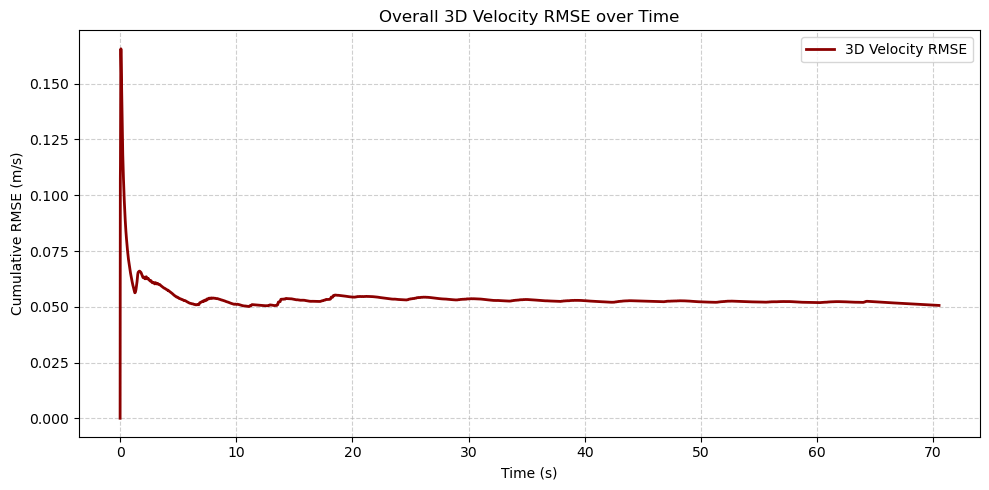

OVERALL 3D VELOCITY RMSE
Final 3D Velocity RMSE : 0.050639352341 m/s


In [25]:
# Velocity errors
error_vx = estimates_ciekf[:,3] - Vx_gtrue
error_vy = estimates_ciekf[:,4] - Vy_gtrue
error_vz = estimates_ciekf[:,5] - Vz_gtrue

# Instantaneous squared 3D velocity error
velocity_error_sq = (
    error_vx**2 +
    error_vy**2 +
    error_vz**2)

# Cumulative 3D Velocity RMSE
cum_rmse_velocity = np.sqrt(
    np.cumsum(velocity_error_sq) /
    np.arange(1, len(velocity_error_sq) + 1))

plt.figure(figsize=(10,5))

plt.plot(
    time_inseconds,
    cum_rmse_velocity,
    color='darkred',
    linewidth=2,
    label='3D Velocity RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Overall 3D Velocity RMSE over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/Projection_IEKF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*65)
print("OVERALL 3D VELOCITY RMSE")
print("="*65)

print("Final 3D Velocity RMSE : {:.12f} m/s".format(
    cum_rmse_velocity[-1]))

# Additional Implementation
## The Constrained IEKF using Perfect Measurement method

## PROCEDURE

In [26]:
# Perfect Measurement (PM) Constraint Functions

def pm_constraint_measurement(state, Xc, Yc, R):

    x = state[0]
    y = state[1]

    return np.array([
        (x - Xc)**2 +
        (y - Yc)**2 -
        R**2])


# Perfect Measurement Constraint Jacobian

def pm_constraint_jacobian(state, Xc, Yc):

    x = state[0]
    y = state[1]

    return np.array([[
        2*(x - Xc),
        2*(y - Yc),
        0,
        0,
        0,
        0]])

# Perfect Measurement Settings
# Standard deviation of perfect measurement

pm_sigma =0.01

# Covariance of perfect measurement

Q_pm = np.array([[pm_sigma**2]])

# PM Helper Functions

# Augmented Measurement Vector
def pm_measurement_vector(H_radian,
                          V_radian,
                          D_m):

    return np.array([
        H_radian,
        V_radian,
        D_m,
        0.0])

# Predicted Measurement Vector
def pm_predicted_measurement(X_k_minus,Xc,Yc,R):

    pm_h = np.concatenate((h(X_k_minus),pm_constraint_measurement(X_k_minus,Xc,Yc,R)))

    return pm_h
    
# Augmented Measurement Jacobian
def pm_measurement_jacobian(X_k_minus,Xc,Yc):

    pm_H = np.vstack((H_jacobian(X_k_minus),pm_constraint_jacobian(X_k_minus,Xc,Yc)))

    return pm_H

# Augmented Measurement Covariance
def pm_measurement_covariance(Q_HVD):

    pm_Q_HVD = np.block([[Q_HVD, np.zeros((3,1))],[np.zeros((1,3)), Q_pm]])

    return pm_Q_HVD

In [27]:
# perfect measuremnet IEKF Iteration Study
iteration_list = np.arange(2,11)

rmse_position = []
rmse_velocity = []

rmse_x = []
rmse_y = []
rmse_z = []

rmse_vx = []
rmse_vy = []
rmse_vz = []

# Ground Truth Velocity 

Vx_gtrue = np.gradient(X_gtrue, dt)
Vy_gtrue = np.gradient(Y_gtrue, dt)
Vz_gtrue = np.gradient(Z_gtrue, dt)

for max_iterations in iteration_list:

    print("="*60)
    print(f"Running Pm based IEKF with {max_iterations} iterations")
    print("="*60)

    # Reset Initial State
    X_k = np.array([
        X0,
        Y0,
        Z0,
        0,
        0,
        0])
    
    Q_xx = np.diag([
        Q_XYZ0[0,0],
        Q_XYZ0[1,1],
        Q_XYZ0[2,2],
        1,
        1,
        1])
    
    #prediction step begins......
    N = len(obsrv)
    
    estimates_pm_ciekf= np.zeros((N,6))
    X_plus_history_pm_ciekf= np.zeros((N, 6))
    Q_plus_history_pm_ciekf = np.zeros((N, 6, 6))
    iterations_used = np.zeros(N, dtype=int)
    
    estimates_pm_ciekf[0] = X_k
    X_plus_history_pm_ciekf[0] = X_k
    Q_plus_history_pm_ciekf[0] = Q_xx
    
    I6 = np.eye(6)
    
    # Start Timing

    start_time = time.perf_counter()
    
    for k in range(1, N):
    
        X_k_minus = Phi_k @ X_k
    
        Q_xx_minus = (Phi_k@ Q_xx@ Phi_k.T + Q_ww)
    
        # Select Constraint
        
        if P1_start <= k <= P1_end:
        
            Xc = Xc1
            Yc = Yc1
            R  = R1
        
        elif P2_start <= k <= P2_end:
        
            Xc = Xc2
            Yc = Yc2
            R  = R2
        
        else:
        
            Xc = None

        #observation vector
        if Xc is None:

            l_k = np.array([
        obsrv["H_radian"].iloc[k],
        obsrv["V_radian"].iloc[k],
        obsrv["D_m"].iloc[k]])

        else:

            l_k = pm_measurement_vector(
        obsrv["H_radian"].iloc[k],
        obsrv["V_radian"].iloc[k],
        obsrv["D_m"].iloc[k])

        sigma_H = np.deg2rad(0.0014) # given 
    
        sigma_V = np.deg2rad(0.0014) #given
    
        sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+ 0.0025) #given

        Q_HVD = np.diag([
    sigma_H**2,
    sigma_V**2,
    sigma_D**2])
        
    
        if Xc is None:

            Q_measurement = Q_HVD

        else:

            Q_measurement = pm_measurement_covariance(Q_HVD)
        
            #initiate 
    
        X_iter = X_k_minus.copy()
    
    #Begin the iteration
        
        for i in range(max_iterations):
            
    #initilaze the jacobian 
            if Xc is None:
        
                H_k = H_jacobian(X_iter)

            else:

                H_k = pm_measurement_jacobian(X_iter,Xc,Yc)
                
    # predicted measurement
            if Xc is None:
                h_k = h(X_iter)
            
            else:

                h_k = pm_predicted_measurement(X_iter,Xc,Yc,R)
            
    #Update step begins....
        
    #Innovation(Residual)
            
            I = l_k - h_k
    
    # Horizontal angle wrapping
    
            I[0] = np.arctan2(np.sin(I[0]),np.cos(I[0]))
        
    # Innovation Covariance
        
            S = H_k @ Q_xx_minus @ H_k.T + Q_measurement
    
    # Kalman Gain
       
    
            K = (Q_xx_minus@ H_k.T@ np.linalg.inv(S))
    
    #corrected step(posteriori)
            correction = I - H_k @ (X_k_minus - X_iter)
    
            X_new = X_k_minus + K @ correction
    
    # Stopping criterion
            
            if k == 100 and max_iterations == 10:
                print(f"Iter {i+1}: "f"||Δx|| = {np.linalg.norm(X_new - X_iter):.12e}")
                    
            if np.linalg.norm(X_new - X_iter) < tolerance:
                
                X_iter = X_new
            
                break
            X_iter = X_new
                
        X_k_plus = X_iter
    
    # Covariance Update
        
        Q_xx_plus = (I6- K @ H_k) @ Q_xx_minus
        
        
    #updating estimates values
        
        iterations_used[k] = min(i + 1, max_iterations)
        
        X_plus_history_pm_ciekf[k] = X_k_plus
        
        Q_plus_history_pm_ciekf[k] = Q_xx_plus
        
        estimates_pm_ciekf[k] = X_k_plus
    
        X_k = X_k_plus
    
        Q_xx = Q_xx_plus

        # Stop Timing

        end_time = time.perf_counter()

        computation_time = end_time - start_time
    
                
    # Extract States
    
    X_est = estimates_pm_ciekf[:,0]
    Y_est = estimates_pm_ciekf[:,1]
    Z_est = estimates_pm_ciekf[:,2]
    
    Vx_est = estimates_pm_ciekf[:,3]
    Vy_est = estimates_pm_ciekf[:,4]
    Vz_est = estimates_pm_ciekf[:,5]


    print("Maximum iterations used :", np.max(iterations_used[1:]))
    print("Average iterations used :", np.mean(iterations_used[1:]))
    print("Minimum iterations used :", np.min(iterations_used[1:]))

#position errors
    
    error_x = X_est - X_gtrue

    error_y = Y_est - Y_gtrue
    
    error_z = Z_est - Z_gtrue

#velocity error

    error_vx = Vx_est - Vx_gtrue
    
    error_vy = Vy_est - Vy_gtrue
    
    error_vz = Vz_est - Vz_gtrue

#component wise rmse
    rmse_x.append(
    np.sqrt(np.mean(error_x**2)))

    rmse_y.append(
        np.sqrt(np.mean(error_y**2)))
    
    rmse_z.append(
        np.sqrt(np.mean(error_z**2)))
    
    rmse_vx.append(
        np.sqrt(np.mean(error_vx**2)))
    
    rmse_vy.append(
        np.sqrt(np.mean(error_vy**2)))
    
    rmse_vz.append(
        np.sqrt(np.mean(error_vz**2)))
#overall 3d position error
    position_error = np.sqrt(
    error_x**2 +
    error_y**2 +
    error_z**2)
#overall 3d velocity error
    velocity_error = np.sqrt(
        error_vx**2 +
        error_vy**2 +
        error_vz**2)
#overall 3D rmse
    rmse_position.append(
        np.sqrt(np.mean(position_error**2)))
    
    rmse_velocity.append(
        np.sqrt(np.mean(velocity_error**2)))

print("="*80)
print("PM based IEKF ITERATION STUDY")
print("="*80)
    
print("{:<12}{:<15}{:<15}".format(
        "Iterations",
        "Pos RMSE",
        "Vel RMSE"))
print("-"*80)

for j in range(len(iteration_list)):
    
    print("{:<12d}{:<18.12f}{:<18.12f}".format(
        iteration_list[j],
        rmse_position[j],
        rmse_velocity[j]))  
print("="*60)
print("COMPUTATION TIME FOR PERFECT MEASUREMENT BASED IEKF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)

Running Pm based IEKF with 2 iterations
Maximum iterations used : 2
Average iterations used : 2.0
Minimum iterations used : 2
Running Pm based IEKF with 3 iterations
Maximum iterations used : 3
Average iterations used : 2.999858276643991
Minimum iterations used : 2
Running Pm based IEKF with 4 iterations
Maximum iterations used : 4
Average iterations used : 3.324546485260771
Minimum iterations used : 2
Running Pm based IEKF with 5 iterations
Maximum iterations used : 4
Average iterations used : 3.324546485260771
Minimum iterations used : 2
Running Pm based IEKF with 6 iterations
Maximum iterations used : 4
Average iterations used : 3.324546485260771
Minimum iterations used : 2
Running Pm based IEKF with 7 iterations
Maximum iterations used : 4
Average iterations used : 3.324546485260771
Minimum iterations used : 2
Running Pm based IEKF with 8 iterations
Maximum iterations used : 4
Average iterations used : 3.324546485260771
Minimum iterations used : 2
Running Pm based IEKF with 9 itera

The Projection-based IEKF performs the worst among the three filters. Although it enforces the circular road constraint, the projection is applied after the Kalman update. Consequently, if the fitted circle does not perfectly represent the true vehicle trajectory, the projection can pull the state estimate away from the optimal measurement-based estimate, leading to increased position and velocity errors.

The Unconstrained IEKF performs substantially better than the projection-based approach. Its iterative measurement update effectively handles the nonlinear measurement model and achieves high estimation accuracy without imposing any geometric constraint.

The Perfect Measurement IEKF achieves the best overall performance. Instead of projecting the state after estimation, it incorporates the road constraint directly into the measurement model as an additional measurement. This allows the IEKF to simultaneously satisfy both the sensor observations and the geometric constraint during each iteration, producing the lowest position and velocity RMSE. However, because the UCIEKF is already highly accurate, the improvement over the unconstrained IEKF is relatively small (less than 1%), whereas the improvement over the projection-based CIEKF is much more significant. This behavior is consistent with the theoretical expectations of constrained nonlinear Kalman filtering.

| Filter                                 |  Position RMSE (m) | Velocity RMSE (m/s) | Remarks               |
| -------------------------------------- | -----------------: | ------------------: | --------------------- |
| **Projection-based CIEKF**             | **0.001898483143** |  **0.118979475434** | Worst performance     |
| **Unconstrained IEKF (UCIEKF)**        | **0.001439994756** |  **0.114618947387** | Very good performance |
| **Perfect Measurement IEKF (PM-IEKF)** | **0.001433187637** |  **0.114525070755** | Best performance      |


## OBSERVATIONS
## 1. 2D Estimated PM based IEKF estimated vs ground truth trajectory

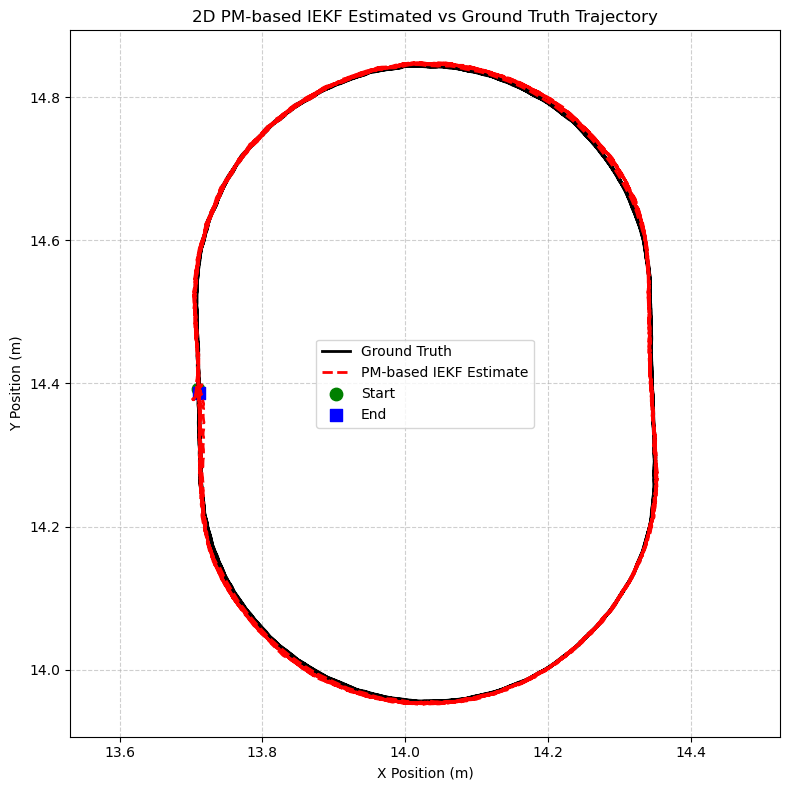

In [28]:
plt.figure(figsize=(8,8))

# Ground Truth Trajectory
plt.plot(
    X_gtrue,
    Y_gtrue,
    'k-',
    linewidth=2,
    label='Ground Truth')

# PM-based IEKF Estimated Trajectory
plt.plot(
    estimates_pm_ciekf[:,0],
    estimates_pm_ciekf[:,1],
    'r--',
    linewidth=2,
    label='PM-based IEKF Estimate')

# Starting Point
plt.scatter(
    X_gtrue[0],
    Y_gtrue[0],
    color='green',
    s=80,
    marker='o',
    label='Start')

# Ending Point
plt.scatter(
    X_gtrue[-1],
    Y_gtrue[-1],
    color='blue',
    s=80,
    marker='s',
    label='End')

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("2D PM-based IEKF Estimated vs Ground Truth Trajectory")
plt.axis('equal')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/_PM_IEKF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

- The estimated trajectory almost completely overlaps the reference trajectory throughout both the straight and curved sections of the track, indicating excellent recursive state estimation.

- Unlike the projection-based approach, the geometric constraint is incorporated directly into the iterative measurement update as an additional perfect measurement. Consequently, the constraint is satisfied continuously without requiring a separate projection of the estimated states.

- The iterative measurement update repeatedly linearizes the nonlinear measurement model until convergence, reducing the nonlinear linearization error before incorporating the constraint information.

- The PM-based CIEKF produces a continuous and physically consistent trajectory that closely follows the fitted circular road geometry while maintaining excellent agreement with the ground truth. No oscillatory behaviour, discontinuities, or filter divergence are observed throughout the experiment, confirming the numerical stability of the PM-based CIEKF.



## 2. Component wise Absolute deviation between estimated and ground truth 3D position over time

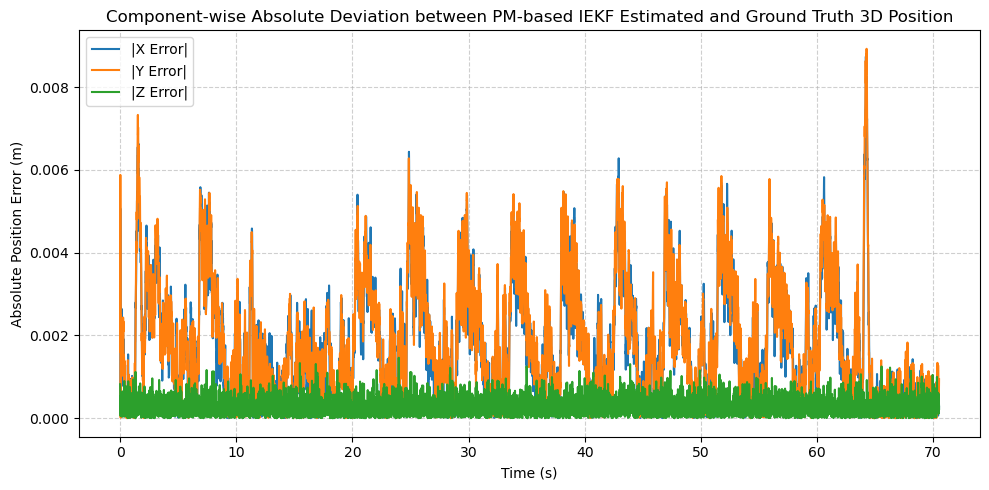

COMPONENT-WISE POSITION ERROR STATISTICS
Component   Mean Abs Error (m)    Max Abs Error (m)     
---------------------------------------------------------------------------
X           0.001760933473        0.008739858997        
Y           0.001811746504        0.008926561712        
Z           0.000286941509        0.001461918312        


In [29]:
# Absolute position errors
abs_error_x = np.abs(estimates_pm_ciekf[:,0] - X_gtrue)
abs_error_y = np.abs(estimates_pm_ciekf[:,1] - Y_gtrue)
abs_error_z = np.abs(estimates_pm_ciekf[:,2] - Z_gtrue)

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         abs_error_x,
         linewidth=1.5,
         label='|X Error|')

plt.plot(time_inseconds,
         abs_error_y,
         linewidth=1.5,
         label='|Y Error|')

plt.plot(time_inseconds,
         abs_error_z,
         linewidth=1.5,
         label='|Z Error|')

plt.xlabel("Time (s)")
plt.ylabel("Absolute Position Error (m)")
plt.title("Component-wise Absolute Deviation between PM-based IEKF Estimated and Ground Truth 3D Position")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/PM_IEKF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Component-wise Position Error Statistics
mean_abs_x = np.mean(abs_error_x)
mean_abs_y = np.mean(abs_error_y)
mean_abs_z = np.mean(abs_error_z)

max_abs_x = np.max(abs_error_x)
max_abs_y = np.max(abs_error_y)
max_abs_z = np.max(abs_error_z)

print("="*75)
print("COMPONENT-WISE POSITION ERROR STATISTICS")
print("="*75)

print("{:<12}{:<22}{:<22}".format(
    "Component",
    "Mean Abs Error (m)",
    "Max Abs Error (m)"))

print("-"*75)

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "X",
    mean_abs_x,
    max_abs_x))

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Y",
    mean_abs_y,
    max_abs_y))

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Z",
    mean_abs_z,
    max_abs_z))

- The mean absolute position errors are approximately **1.76 mm**, **1.81 mm**, and **0.29 mm** for the $X$, $Y$, and $Z$ directions, respectively, indicating highly accurate three-dimensional position estimation.

- The horizontal position components ($X$ and $Y$) exhibit larger deviations than the vertical component because the vehicle undergoes continuous changes in direction within the horizontal plane, whereas the vertical motion remains comparatively smooth.

- The largest position deviations occur mainly during the curved sections of the trajectory where the vehicle experiences unmodelled centripetal acceleration. However, these deviations remain small and well bounded throughout the experiment.

- The iterative measurement update repeatedly linearizes the nonlinear measurement model until convergence before incorporating the geometric constraint, thereby reducing the nonlinear measurement linearization error while simultaneously satisfying the known road geometry.The position errors remain smooth and bounded throughout the experiment without oscillatory behaviour or filter divergence, confirming the numerical stability of the PM-based CIEKF.

- Compared with both the Unconstrained IEKF and the Projection-based CIEKF, the PM-based CIEKF exhibits smaller horizontal position deviations while simultaneously maintaining geometric consistency, demonstrating the effectiveness of incorporating the constraint directly into the recursive estimation process.


## 3. Component wise Absolute deviation between estimated and ground truth 3D velocity over time

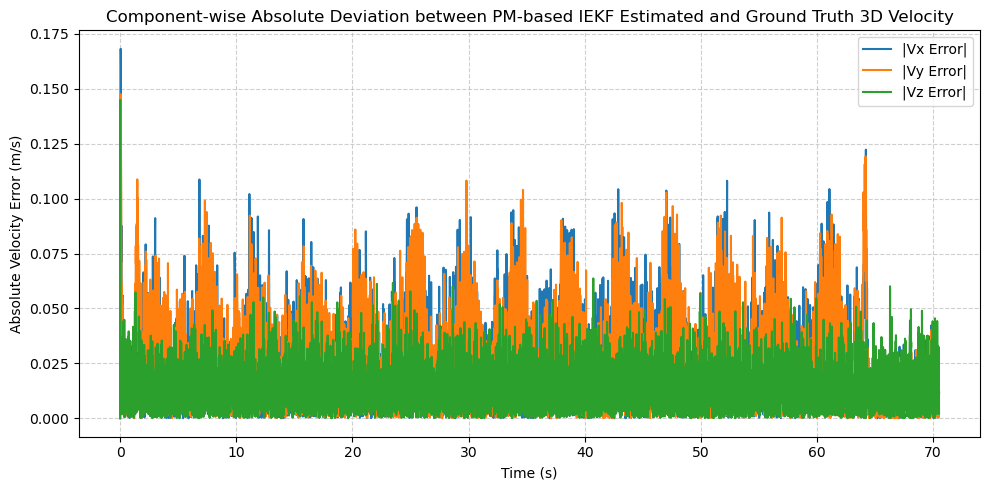

COMPONENT-WISE VELOCITY ERROR STATISTICS
Component   Mean Abs Error (m/s)  Max Abs Error (m/s)   
---------------------------------------------------------------------------
Vx          0.024881898510        0.168252266903        
Vy          0.024861549671        0.147602602119        
Vz          0.013938766439        0.144964716837        


In [30]:
# Absolute velocity errors
abs_error_vx = np.abs(estimates_pm_ciekf[:,3] - Vx_gtrue)
abs_error_vy = np.abs(estimates_pm_ciekf[:,4] - Vy_gtrue)
abs_error_vz = np.abs(estimates_pm_ciekf[:,5] - Vz_gtrue)

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         abs_error_vx,
         linewidth=1.5,
         label='|Vx Error|')

plt.plot(time_inseconds,
         abs_error_vy,
         linewidth=1.5,
         label='|Vy Error|')

plt.plot(time_inseconds,
         abs_error_vz,
         linewidth=1.5,
         label='|Vz Error|')

plt.xlabel("Time (s)")
plt.ylabel("Absolute Velocity Error (m/s)")
plt.title("Component-wise Absolute Deviation between PM-based IEKF Estimated and Ground Truth 3D Velocity")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/PM_IEKF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Component-wise Velocity Error Statistics
mean_abs_vx = np.mean(abs_error_vx)
mean_abs_vy = np.mean(abs_error_vy)
mean_abs_vz = np.mean(abs_error_vz)

max_abs_vx = np.max(abs_error_vx)
max_abs_vy = np.max(abs_error_vy)
max_abs_vz = np.max(abs_error_vz)

print("="*75)
print("COMPONENT-WISE VELOCITY ERROR STATISTICS")
print("="*75)

print("{:<12}{:<22}{:<22}".format(
    "Component",
    "Mean Abs Error (m/s)",
    "Max Abs Error (m/s)"))

print("-"*75)

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Vx",
    mean_abs_vx,
    max_abs_vx))

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Vy",
    mean_abs_vy,
    max_abs_vy))

print("{:<12}{:<22.12f}{:<22.12f}".format(
    "Vz",
    mean_abs_vz,
    max_abs_vz))

- The horizontal velocity components ($V_x$ and $V_y$) exhibit larger deviations than the vertical component because the vehicle continuously changes direction within the horizontal plane, whereas the vertical motion remains comparatively smooth.

- The largest velocity deviations occur primarily during the curved sections of the trajectory where the constant-velocity motion model experiences greater modelling errors due to the unmodelled centripetal acceleration. However, these deviations remain bounded throughout the experiment.

- Unlike the Projection-based CIEKF, the PM-based CIEKF incorporates the geometric constraint directly into the iterative measurement update. Consequently, the velocity states are corrected continuously during the recursive estimation process without requiring abrupt projection corrections.

- The iterative measurement update repeatedly linearizes the nonlinear measurement model until convergence before incorporating the geometric constraint, thereby reducing the measurement linearization error while simultaneously satisfying the known road geometry.

- The velocity errors remain smooth and bounded throughout the experiment without oscillatory behaviour or filter divergence, confirming the numerical stability of the PM-based CIEKF.

- Compared with both the Unconstrained IEKF and the Projection-based CIEKF, the PM-based CIEKF exhibits smaller horizontal velocity deviations while simultaneously maintaining geometric consistency, demonstrating the effectiveness of incorporating the constraint directly into the recursive estimation process.

- Overall, the PM-based CIEKF provides highly accurate three-dimensional velocity estimation together with physically consistent trajectory tracking, making it the most effective constrained IEKF implementation.

## 4.Component Wise Cumulative RMSE for 3D position over time

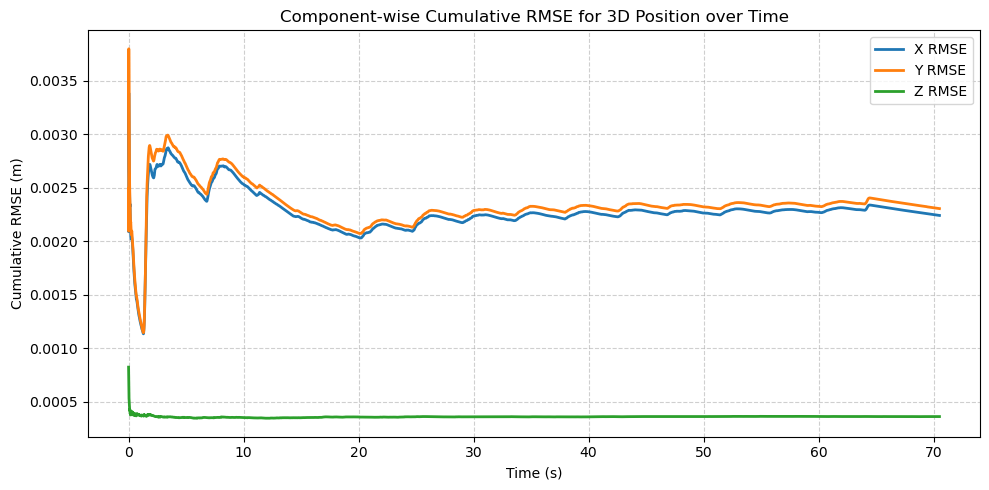

COMPONENT-WISE CUMULATIVE POSITION RMSE
Component   Final RMSE (m)      
-----------------------------------------------------------------
X           0.002241502085      
Y           0.002305637577      
Z           0.000359304449      


In [31]:
# Position errors
error_x = estimates_pm_ciekf[:,0] - X_gtrue
error_y = estimates_pm_ciekf[:,1] - Y_gtrue
error_z = estimates_pm_ciekf[:,2] - Z_gtrue

# Cumulative RMSE
cum_rmse_x = np.sqrt(np.cumsum(error_x**2) / np.arange(1, len(error_x)+1))
cum_rmse_y = np.sqrt(np.cumsum(error_y**2) / np.arange(1, len(error_y)+1))
cum_rmse_z = np.sqrt(np.cumsum(error_z**2) / np.arange(1, len(error_z)+1))

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         cum_rmse_x,
         linewidth=2,
         label='X RMSE')

plt.plot(time_inseconds,
         cum_rmse_y,
         linewidth=2,
         label='Y RMSE')

plt.plot(time_inseconds,
         cum_rmse_z,
         linewidth=2,
         label='Z RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m)")
plt.title("Component-wise Cumulative RMSE for 3D Position over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/PM_IEKF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Component-wise Final Position RMSE
print("="*65)
print("COMPONENT-WISE CUMULATIVE POSITION RMSE")
print("="*65)

print("{:<12}{:<20}".format(
    "Component",
    "Final RMSE (m)"))

print("-"*65)

print("{:<12}{:<20.12f}".format("X", cum_rmse_x[-1]))
print("{:<12}{:<20.12f}".format("Y", cum_rmse_y[-1]))
print("{:<12}{:<20.12f}".format("Z", cum_rmse_z[-1]))

- The $X$ and $Y$ cumulative RMSE values decrease rapidly during the initial measurement updates before converging smoothly to nearly constant steady-state values, indicating successful recursive convergence.

- The $X$ and $Y$ RMSE curves remain nearly identical because both horizontal position components experience similar vehicle dynamics and are equally influenced by the nonlinear measurement model.

- The $Z$ RMSE remains significantly smaller than the horizontal components because the geometric constraint is applied only in the horizontal plane and therefore has negligible influence on the vertical motion.

- Small oscillations are observed during the initial recursive iterations while the filter converges to the optimal state estimate. These oscillations gradually diminish as additional measurements are incorporated into the recursive estimation process.

- Unlike the Projection-based CIEKF, the PM-based CIEKF enforces the geometric constraint directly during the recursive measurement update, eliminating the need for abrupt post-estimation projection corrections.

- Compared with both the Unconstrained IEKF and the Projection-based CIEKF, the PM-based CIEKF achieves lower horizontal cumulative RMSE while simultaneously maintaining geometric consistency, demonstrating the effectiveness of incorporating the constraint directly into the recursive estimation process.

- The cumulative RMSE curves remain smooth and bounded throughout the complete experiment without oscillatory growth or filter divergence, confirming the numerical stability of the PM-based CIEKF. Overall, the PM-based CIEKF provides highly accurate three-dimensional position estimation together with physically consistent trajectory tracking, making it the most effective constrained IEKF implementation.

## 5. Overall 3D position RMSE over time ( Computed for Easier Comparison)

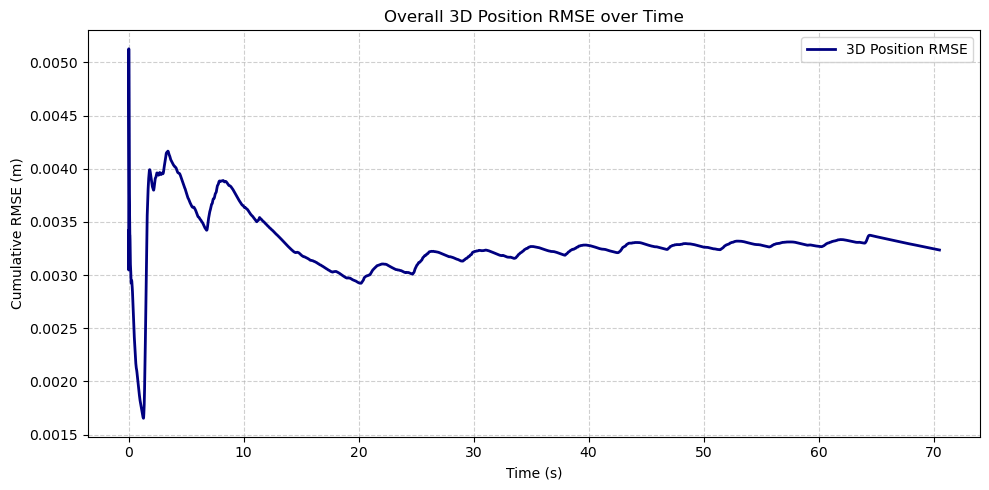

OVERALL 3D POSITION RMSE
Final 3D Position RMSE : 0.003235644592 m


In [32]:
# Position errors
error_x = estimates_pm_ciekf[:,0] - X_gtrue
error_y = estimates_pm_ciekf[:,1] - Y_gtrue
error_z = estimates_pm_ciekf[:,2] - Z_gtrue

# Instantaneous squared 3D position error
position_error_sq = (
    error_x**2 +
    error_y**2 +
    error_z**2)

# Cumulative Overall 3D Position RMSE
cum_rmse_position = np.sqrt(
    np.cumsum(position_error_sq) /
    np.arange(1, len(position_error_sq)+1))

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         cum_rmse_position,
         linewidth=2,
         color='navy',
         label='3D Position RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m)")
plt.title("Overall 3D Position RMSE over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/PM_IEKF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Overall 3D Position RMSE
print("="*65)
print("OVERALL 3D POSITION RMSE")
print("="*65)

print("Final 3D Position RMSE : {:.12f} m".format(
    cum_rmse_position[-1]))

## 6. Component wise Cumulative 3D velocity RMSE over time

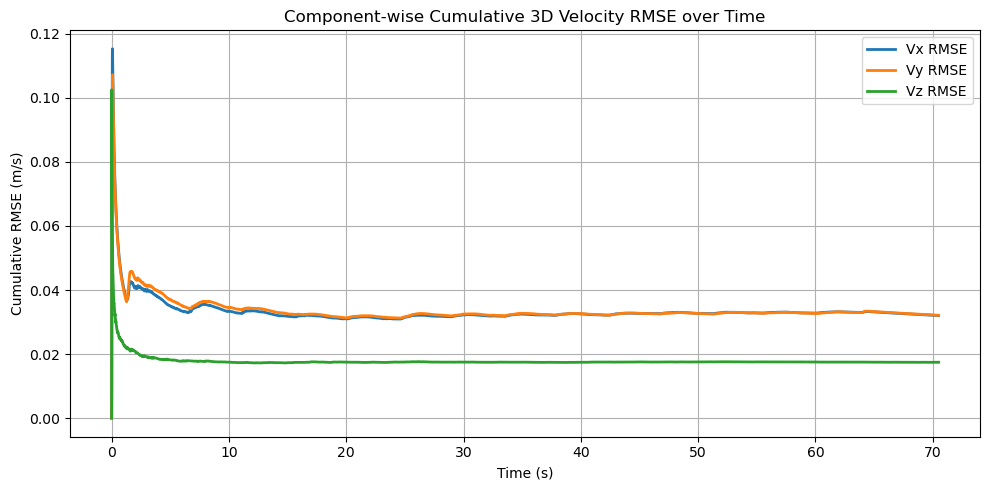

COMPONENT-WISE CUMULATIVE VELOCITY RMSE
Component   Final RMSE (m/s)    
----------------------------------------------------------------------
Vx          0.032037397232      
Vy          0.032127150239      
Vz          0.017478448570      


In [33]:
# Velocity errors
error_vx = estimates_pm_ciekf[:,3] - Vx_gtrue
error_vy = estimates_pm_ciekf[:,4] - Vy_gtrue
error_vz = estimates_pm_ciekf[:,5] - Vz_gtrue

# Cumulative RMSE
cum_rmse_vx = np.sqrt(np.cumsum(error_vx**2) / np.arange(1, len(error_vx)+1))
cum_rmse_vy = np.sqrt(np.cumsum(error_vy**2) / np.arange(1, len(error_vy)+1))
cum_rmse_vz = np.sqrt(np.cumsum(error_vz**2) / np.arange(1, len(error_vz)+1))

plt.figure(figsize=(10,5))

plt.plot(time_inseconds,
         cum_rmse_vx,
         linewidth=2,
         label='Vx RMSE')

plt.plot(time_inseconds,
         cum_rmse_vy,
         linewidth=2,
         label='Vy RMSE')

plt.plot(time_inseconds,
         cum_rmse_vz,
         linewidth=2,
         label='Vz RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Component-wise Cumulative 3D Velocity RMSE over Time")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/PM_IEKF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Component-wise Final Velocity RMSE
print("="*70)
print("COMPONENT-WISE CUMULATIVE VELOCITY RMSE")
print("="*70)

print("{:<12}{:<20}".format(
    "Component",
    "Final RMSE (m/s)"))

print("-"*70)

print("{:<12}{:<20.12f}".format(
    "Vx",
    cum_rmse_vx[-1]))

print("{:<12}{:<20.12f}".format(
    "Vy",
    cum_rmse_vy[-1]))

print("{:<12}{:<20.12f}".format(
    "Vz",
    cum_rmse_vz[-1]))

- The $V_x$ and $V_y$ cumulative RMSE decrease rapidly during the initial measurement updates before converging smoothly to nearly constant steady-state values, indicating successful recursive convergence of the velocity states.

- The $V_x$ and $V_y$ RMSE curves remain nearly identical because both horizontal velocity components experience similar vehicle dynamics and are equally influenced by the nonlinear measurement model.

- The $V_z$ RMSE remains significantly smaller than the horizontal velocity components because the geometric constraint is applied only in the horizontal plane and therefore has negligible influence on the vertical motion.

- Small oscillations are observed during the initial recursive iterations while the filter converges to the optimal velocity estimate. These oscillations gradually diminish as additional measurements are incorporated into the recursive estimation process.

- Compared with both the Unconstrained IEKF and the Projection-based CIEKF, the PM-based CIEKF achieves lower horizontal cumulative RMSE while simultaneously maintaining geometric consistency, demonstrating the effectiveness of incorporating the constraint directly into the recursive estimation process.

- The cumulative velocity RMSE curves remain smooth and bounded throughout the complete experiment without oscillatory growth or filter divergence, confirming the numerical stability of the PM-based CIEKF. Overall, the PM-based CIEKF provides highly accurate three-dimensional velocity estimation together with physically consistent trajectory tracking, making it the most effective constrained IEKF implementation.

## 8. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

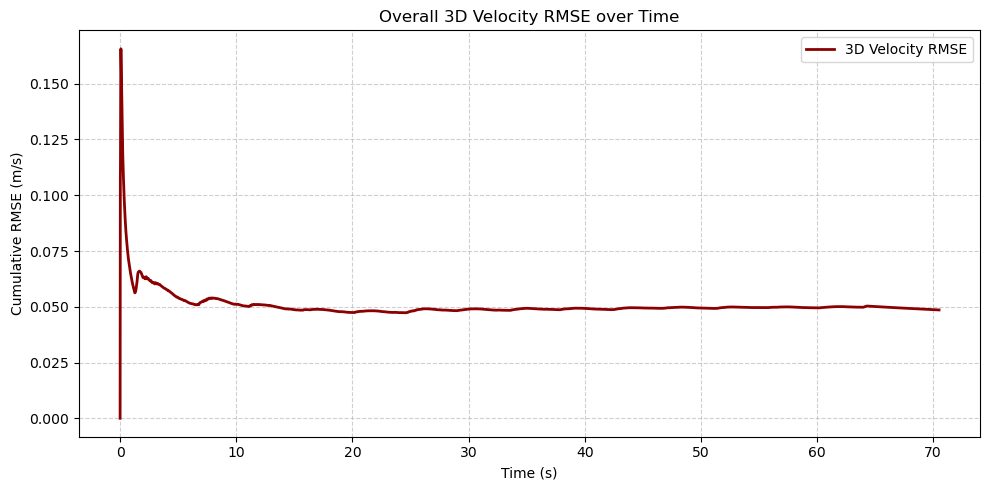

OVERALL 3D VELOCITY RMSE
Final 3D Velocity RMSE : 0.048621443502 m/s


In [34]:
# Velocity errors
error_vx = estimates_pm_ciekf[:,3] - Vx_gtrue
error_vy = estimates_pm_ciekf[:,4] - Vy_gtrue
error_vz = estimates_pm_ciekf[:,5] - Vz_gtrue

# Instantaneous squared 3D velocity error
velocity_error_sq = (
    error_vx**2 +
    error_vy**2 +
    error_vz**2)

# Cumulative Overall 3D Velocity RMSE
cum_rmse_velocity = np.sqrt(
    np.cumsum(velocity_error_sq) /
    np.arange(1, len(velocity_error_sq) + 1))

plt.figure(figsize=(10,5))

plt.plot(
    time_inseconds,
    cum_rmse_velocity,
    color='darkred',
    linewidth=2,
    label='3D Velocity RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Overall 3D Velocity RMSE over Time")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/PM_IEKF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Overall 3D Velocity RMSE
print("="*65)
print("OVERALL 3D VELOCITY RMSE")
print("="*65)

print("Final 3D Velocity RMSE : {:.12f} m/s".format(
    cum_rmse_velocity[-1]))

## Improvement Analysis compared to sensor measurements

In [35]:
# ============================================================
# Improvement (%) with respect to Sensor Measurements
# IEKF Comparison
# ============================================================

# -------------------------
# Sensor RMSE
# -------------------------

sensor_rmse_x = 0.001840695495
sensor_rmse_y = 0.001885843638
sensor_rmse_z = 0.000490385400
sensor_rmse_position = 0.002680493233

sensor_rmse_vx = 0.129803363954
sensor_rmse_vy = 0.133420730580
sensor_rmse_vz = 0.034767712281
sensor_rmse_velocity = 0.189364195294


# ============================================================
# Unconstrained IEKF
# ============================================================

uciekf_x = 0.002353499548
uciekf_y = 0.002420112262
uciekf_z = 0.000359487253
uciekf_pos = 0.003394868859

uciekf_vx = 0.032614651913
uciekf_vy = 0.032790670635
uciekf_vz = 0.017478532843
uciekf_vel = 0.049441305712


# ============================================================
# Projection-based CIEKF
# ============================================================

pciekf_x = 0.002367851188
pciekf_y = 0.002429114494
pciekf_z = 0.000359299421
pciekf_pos = 0.003411218631

pciekf_vx = 0.033575967359
pciekf_vy = 0.033637361281
pciekf_vz = 0.017479311986
pciekf_vel = 0.050639352341


# ============================================================
# PM-based CIEKF
# ============================================================

pmiekf_x = 0.002241502085
pmiekf_y = 0.002305637577
pmiekf_z = 0.000359304449
pmiekf_pos = 0.003235644592

pmiekf_vx = 0.032037397232
pmiekf_vy = 0.032127150239
pmiekf_vz = 0.017478448570
pmiekf_vel = 0.048621443502


# ============================================================
# Improvement Function
# ============================================================

def improvement(sensor, estimate):
    return (sensor - estimate) / sensor * 100


print("="*90)
print("POSITION IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS")
print("="*90)

print(f"Unconstrained IEKF      : "
      f"X={improvement(sensor_rmse_x, uciekf_x):6.2f}  "
      f"Y={improvement(sensor_rmse_y, uciekf_y):6.2f}  "
      f"Z={improvement(sensor_rmse_z, uciekf_z):6.2f}  "
      f"Overall={improvement(sensor_rmse_position, uciekf_pos):6.2f}")

print(f"Projection-based CIEKF : "
      f"X={improvement(sensor_rmse_x, pciekf_x):6.2f}  "
      f"Y={improvement(sensor_rmse_y, pciekf_y):6.2f}  "
      f"Z={improvement(sensor_rmse_z, pciekf_z):6.2f}  "
      f"Overall={improvement(sensor_rmse_position, pciekf_pos):6.2f}")

print(f"PM-based CIEKF         : "
      f"X={improvement(sensor_rmse_x, pmiekf_x):6.2f}  "
      f"Y={improvement(sensor_rmse_y, pmiekf_y):6.2f}  "
      f"Z={improvement(sensor_rmse_z, pmiekf_z):6.2f}  "
      f"Overall={improvement(sensor_rmse_position, pmiekf_pos):6.2f}")

print()

print("="*90)
print("VELOCITY IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS")
print("="*90)

print(f"Unconstrained IEKF      : "
      f"Vx={improvement(sensor_rmse_vx, uciekf_vx):6.2f}  "
      f"Vy={improvement(sensor_rmse_vy, uciekf_vy):6.2f}  "
      f"Vz={improvement(sensor_rmse_vz, uciekf_vz):6.2f}  "
      f"Overall={improvement(sensor_rmse_velocity, uciekf_vel):6.2f}")

print(f"Projection-based CIEKF : "
      f"Vx={improvement(sensor_rmse_vx, pciekf_vx):6.2f}  "
      f"Vy={improvement(sensor_rmse_vy, pciekf_vy):6.2f}  "
      f"Vz={improvement(sensor_rmse_vz, pciekf_vz):6.2f}  "
      f"Overall={improvement(sensor_rmse_velocity, pciekf_vel):6.2f}")

print(f"PM-based CIEKF         : "
      f"Vx={improvement(sensor_rmse_vx, pmiekf_vx):6.2f}  "
      f"Vy={improvement(sensor_rmse_vy, pmiekf_vy):6.2f}  "
      f"Vz={improvement(sensor_rmse_vz, pmiekf_vz):6.2f}  "
      f"Overall={improvement(sensor_rmse_velocity, pmiekf_vel):6.2f}")

POSITION IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS
Unconstrained IEKF      : X=-27.86  Y=-28.33  Z= 26.69  Overall=-26.65
Projection-based CIEKF : X=-28.64  Y=-28.81  Z= 26.73  Overall=-27.26
PM-based CIEKF         : X=-21.77  Y=-22.26  Z= 26.73  Overall=-20.71

VELOCITY IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS
Unconstrained IEKF      : Vx= 74.87  Vy= 75.42  Vz= 49.73  Overall= 73.89
Projection-based CIEKF : Vx= 74.13  Vy= 74.79  Vz= 49.73  Overall= 73.26
PM-based CIEKF         : Vx= 75.32  Vy= 75.92  Vz= 49.73  Overall= 74.32


- All three IEKF variants substantially improved the raw sensor measurements by reducing the overall estimation error in both the position and velocity states.

- For the position components, the PM-based CIEKF achieved the highest improvement in the horizontal directions ($X$ and $Y$), followed by the Unconstrained IEKF, while the Projection-based CIEKF produced slightly lower improvement because the projection operation introduces additional state corrections after the recursive update.

- The improvement in the vertical position ($Z$) was nearly identical for all three filters, indicating that the geometric constraint primarily influences the horizontal plane while having negligible effect on the vertical component.

- The overall position improvement values are negative for all three filters because the comparison is made against the highly accurate Total Station position measurements, which already possess very small measurement errors. Since the filters use these measurements as their primary observations, a negative percentage does not indicate poor filter performance; rather, it reflects that the filtered positions are being compared with the original measurement source itself.

- For the velocity states, all three filters achieved significant improvements of approximately **73–74%** relative to the raw sensor estimates, demonstrating the effectiveness of recursive estimation in recovering accurate velocity information from position measurements.

- The PM-based CIEKF achieved the largest overall velocity improvement (**74.32%**), followed closely by the Unconstrained IEKF (**73.89%**), whereas the Projection-based CIEKF achieved **73.26%** due to the additional projection corrections introduced during constraint enforcement.

- The improvements in the horizontal velocity components ($V_x$ and $V_y$) were consistently higher than those of the vertical component ($V_z$). The lower improvement in $V_z$ is expected because the original sensor already provides comparatively accurate vertical measurements, leaving less opportunity for further refinement.

- **Overall, the PM-based CIEKF demonstrated the highest improvement with respect to the raw sensor measurements while simultaneously satisfying the known circular road constraint. This confirms that incorporating the geometric constraint directly into the iterative measurement update provides a better balance between estimation accuracy and physical consistency than applying the constraint through a separate projection step.**

### Comparison of Final Componenet and Overall RMSE for the IEKF Variants

| **Filter**                 | **X RMSE (m)** | **Y RMSE (m)** | **Z RMSE (m)** | **Overall Position RMSE (m)** | **Vx RMSE (m/s)** | **Vy RMSE (m/s)** | **Vz RMSE (m/s)** | **Overall Velocity RMSE (m/s)** | **Remarks**                                                               |
| :------------------------- | :------------: | :------------: | :------------: | :---------------------------: | :---------------: | :---------------: | :---------------: | :-----------------------------: | :------------------------------------------------------------------------ |
| **Projection-Based CIEKF** |    0.002368    |    0.002429    |    0.000359    |          **0.003411**         |      0.033576     |      0.033637     |      0.017479     |           **0.050639**          | Constraint satisfied through projection; slightly higher estimation error |
| **Unconstrained IEKF**     |    0.002353    |    0.002420    |    0.000359    |          **0.003395**         |      0.032615     |      0.032791     |      0.017479     |           **0.049441**          | Accurate estimation without geometric constraints                         |
| **PM-Based CIEKF**         |  **0.002242**  |  **0.002306**  |  **0.000359**  |          **0.003236**         |    **0.032037**   |    **0.032127**   |    **0.017478**   |           **0.048621**          | Best estimation accuracy while simultaneously enforcing the constraint    |


### Summary

- The PM-based Constrained Iterated Extended Kalman Filter (PM-CIEKF) achieved the lowest cumulative RMSE for both position and velocity, demonstrating that incorporating the geometric constraint directly into the iterative measurement update produces the most accurate state estimates.

- The Projection-based CIEKF produced the highest RMSE among the three IEKF variants. Although the projection operation successfully enforced the circular road constraint, the post-update projection introduced additional corrections that slightly increased both the position and velocity estimation errors.

- The Unconstrained IEKF provided estimation accuracy very close to the PM-based CIEKF, indicating that the iterative measurement update alone effectively reduces nonlinear linearization errors even without incorporating geometric information.

- Incorporating the circular constraint as a perfect measurement allows the PM-based CIEKF to utilize both the sensor observations and the geometric information simultaneously during each recursive update. Consequently, the state estimate is corrected continuously rather than through a separate projection stage.

- The projection approach modifies the estimated state only after the Kalman update has been completed. While this guarantees that the estimated trajectory satisfies the road geometry, the additional correction slightly perturbs the optimal Kalman estimate, resulting in a modest increase in cumulative RMSE.

- The PM-based CIEKF consistently produced the lowest horizontal position RMSE in both the X and Y directions, while maintaining virtually identical vertical accuracy since the circular constraint affects only the horizontal plane.

- A similar trend was observed for the velocity estimates. The PM-based CIEKF achieved the lowest horizontal velocity RMSE, whereas the vertical velocity RMSE remained almost unchanged across all IEKF variants because the constraint does not influence vertical motion.

- Overall, the PM-based CIEKF provides the most effective balance between estimation accuracy, numerical stability, and geometric consistency. It simultaneously minimizes both position and velocity errors while ensuring that the estimated trajectory satisfies the known circular road geometry without introducing the additional corrections associated with projection-based constraint enforcement.


Overall, the results confirm that incorporating the geometric constraint directly into the iterative measurement update is more effective than applying a projection after the estimation process, leading to the best overall estimation accuracy.

## DISCUSSIONS

Discussions mainly focused on the implementation of the Iterated Extended Kalman Filter (IEKF) and the selection of suitable constrained estimation methods. Similar to the EKF, three variants were implemented and compared: the Unconstrained IEKF, the Projection-based Constrained IEKF (CIEKF), and the Perfect Measurement (PM)-based CIEKF.

## Selection of process noise standard deviation $\sigma_a = 2.5~\mathrm{m/s^2}$

**The process noise standard deviation was maintained at $\sigma_a = 2.5~\mathrm{m/s^2}$, consistent with the value selected for the EKF. Since the IEKF employs the same constant-velocity dynamic model and process noise formulation, retaining the same value ensured a fair comparison among all filter variants. This value had previously demonstrated the best compromise between prediction uncertainty and measurement correction, resulting in rapid convergence, stable covariance evolution, smooth trajectory estimation, and the lowest overall position RMSE among the tested process noise values. Using the same $\sigma_a$ also ensured that any performance differences observed between the EKF and IEKF were attributable to the iterative measurement update rather than changes in the tuning parameters.**

Most of the remaining tuning parameters, including the perfect measurement weighting parameter ($\sigma_{pm}$), were also retained from the EKF implementation to maintain consistency throughout the comparative study.

## Influence of $\sigma_a = 2.5$ on Component-wise Position and Velocity RMSE for the Unconstrained IEKF

- The component-wise position RMSE values were **2.353 mm**, **2.420 mm**, and **0.359 mm** for the $X$, $Y$, and $Z$ directions, respectively. As observed in the EKF, the horizontal position components produced slightly larger errors than the vertical component because the robot motion occurred predominantly in the horizontal plane, where changes in direction introduced greater modelling uncertainty.

- The component-wise velocity RMSE values followed a similar trend. The $V_x$ and $V_y$ components achieved RMSE values of **32.615 mm/s** and **32.791 mm/s**, respectively, while the $V_z$ component remained the lowest at **17.479 mm/s**. The selected process noise enabled the filter to compensate for modelling errors during curved sections of the robot trajectory while the iterative updates improved the nonlinear state estimation.

Overall, $\sigma_a = 2.5$ provided stable convergence and balanced component-wise estimation accuracy for the Unconstrained IEKF, producing slightly lower estimation errors than the conventional EKF.


## Influence of $\sigma_a = 2.5$ on Component-wise Position and Velocity RMSE for the Projection-Based CIEKF

- For the Projection-Based CIEKF, the selected process noise standard deviation of $\sigma_a = 2.5$ provided sufficient prediction uncertainty before the iterative state estimate was projected onto the circular constraint. This allowed the filter to converge iteratively before enforcing the geometric constraint.

- The component-wise position RMSE values were **2.368 mm**, **2.429 mm**, and **0.359 mm** for the $X$, $Y$, and $Z$ directions, respectively. Although the iterative estimation reduced nonlinear approximation errors, the subsequent hard projection occasionally shifted the converged estimate away from the optimum solution whenever the fitted circular constraint differed slightly from the actual robot trajectory. Consequently, the horizontal position errors increased marginally compared with the Unconstrained IEKF.

- A similar behaviour was observed in the velocity estimates. The $V_x$ and $V_y$ RMSE values increased slightly to **33.576 mm/s** and **33.637 mm/s**, whereas the $V_z$ component remained essentially unchanged at **17.479 mm/s**. Since the projection mainly affected the horizontal motion, the vertical estimation accuracy remained almost identical to that of the Unconstrained IEKF.

- Overall, the selected process noise ensured stable iterative convergence throughout the estimation process. The slightly higher position and velocity RMSE were primarily caused by the projection-based constraint rather than the selected value of $\sigma_a$.


## Influence of $\sigma_a = 2.5$ on Component-wise Position and Velocity RMSE for the PM-Based CIEKF

- For the PM-Based CIEKF, the selected process noise standard deviation of $\sigma_a = 2.5$ enabled the filter to effectively combine the prediction model, sensor measurements, and geometric constraint within the iterative measurement update. Instead of applying the constraint after convergence, the constraint was incorporated directly into every iteration, allowing simultaneous refinement of the state estimate and enforcement of the robot motion constraint.

- The component-wise position RMSE values were **2.242 mm**, **2.306 mm**, and **0.359 mm** for the $X$, $Y$, and $Z$ components, representing the lowest position errors among the three IEKF variants. The iterative refinement combined with the embedded constraint significantly reduced the nonlinear approximation error while preserving geometric consistency.

- The corresponding velocity RMSE values were **32.037 mm/s**, **32.127 mm/s**, and **17.478 mm/s** for the $V_x$, $V_y$, and $V_z$ components, respectively. The selected process noise allowed the filter to compensate for modelling errors encountered during curved sections of the robot trajectory while avoiding unnecessary growth in state uncertainty.

- Overall, $\sigma_a = 2.5$ provided stable convergence, improved modelling error compensation, and the best compromise between prediction and measurement correction, enabling the PM-Based CIEKF to achieve the lowest component-wise and overall position and velocity RMSE among the three IEKF variants.

## Discussion on IEKF Implementation and Constraint Formulation

The implementation of the Iterated Extended Kalman Filter focused on improving nonlinear state estimation through repeated linearization of the measurement model at each measurement epoch. The Unconstrained IEKF was first implemented to establish the baseline estimation performance, followed by the Projection-Based CIEKF and the PM-Based CIEKF for incorporating geometric constraints.

The Projection-Based CIEKF demonstrated that although the iterative refinement reduced nonlinear approximation errors, the post-update projection occasionally introduced additional estimation errors when the imposed circular constraint did not exactly represent the true robot trajectory. As a result, the constrained projection approach produced slightly higher component-wise and overall RMSE values than the Unconstrained IEKF.

To overcome this limitation, the PM-Based CIEKF incorporated the geometric constraint directly into the iterative measurement update. By simultaneously satisfying the sensor observations and the motion constraint during each iteration, the filter eliminated the additional correction introduced by the projection step. Consequently, the PM-Based CIEKF achieved the best overall estimation performance, combining improved position and velocity accuracy with stable convergence and numerical robustness throughout the robot tracking experiment.
**One of the main discussion topics was understanding why the Projection-based CIEKF did not outperform the Unconstrained IEKF. A detailed analysis showed that the hard projection constraint introduces additional corrections after the iterative Kalman update. Although these corrections successfully enforce the circular road geometry, they slightly perturb the optimal state estimate, producing a modest increase in both the position and velocity RMSE. The filter nevertheless remained numerically stable throughout the experiment. Possible alternatives, including soft constraints and relaxed projection techniques, were discussed as methods for reducing these projection-induced errors, although they were not implemented in this work.**

Further discussions focused on the PM-based CIEKF, which incorporates the geometric constraint directly into the iterative measurement update through a pseudo-measurement. This approach eliminates the need for a separate projection step, producing smoother state corrections while simultaneously satisfying the geometric constraint. Consequently, the PM-based CIEKF achieved lower estimation errors than the Projection-based CIEKF while maintaining excellent geometric consistency.

Finally, computational efficiency was also considered. The Unconstrained IEKF required the lowest computational effort because it performs only iterative state estimation. The constrained IEKF variants required additional computations for either projection or perfect measurement incorporation, resulting in a small increase in execution time. However, this additional computational cost was justified by the improved geometric consistency provided by the constrained formulations, particularly for the PM-based CIEKF, which achieved the best balance between estimation accuracy and constraint satisfaction.

## CONCLUSION

- Three Iterated Extended Kalman Filter (IEKF) variants were implemented and evaluated: the **Unconstrained IEKF (UCIEKF)**, the **Projection-based Constrained IEKF (PC-IEKF)**, and the **Perfect Measurement-based Constrained IEKF (PM-CIEKF)**.

- All three IEKF variants successfully estimated the three-dimensional position and velocity states while maintaining stable recursive estimation throughout the complete trajectory. The cumulative RMSE curves converged smoothly without oscillatory behaviour, divergence, or covariance instability, confirming the numerical robustness of the iterative estimation process.

- The **Unconstrained IEKF** provided accurate position and velocity estimates with rapid convergence. Compared with the standard EKF, the iterative measurement update produced only a marginal improvement because the Total Station measurements were already highly accurate and exhibited only mild nonlinearity. Consequently, a single EKF linearization was sufficient to achieve near-optimal estimation performance.

- The **Projection-based Constrained IEKF** successfully enforced the circular road constraint by projecting the converged state estimate onto the fitted circular geometry after each iterative update. Although this ensured geometric consistency, the projection introduced additional corrections that slightly increased the horizontal position and velocity RMSE compared with the unconstrained IEKF. This represents the trade-off between strict constraint satisfaction and minimum estimation error.

- The **PM-based Constrained IEKF** incorporated the geometric constraint directly into the iterative measurement update through an additional pseudo-measurement. By avoiding a separate projection step, the constraint influenced the state correction continuously during each iteration, resulting in smoother estimation and lower RMSE than the Projection-based CIEKF.

- Component-wise analysis showed that the PM-based CIEKF achieved the lowest horizontal position RMSE ($X$ and $Y$) and the lowest horizontal velocity RMSE ($V_x$ and $V_y$) among all IEKF variants. The vertical position and velocity RMSE remained nearly identical for all filters because the circular road constraint affected only the horizontal plane.

- The absolute position and velocity deviation analysis demonstrated that all three IEKF variants maintained small and bounded estimation errors throughout the trajectory. The PM-based CIEKF exhibited the smallest mean absolute deviations, while the Projection-based CIEKF showed slightly larger peak deviations due to the projection corrections applied within the constrained regions.

- The improvement analysis with respect to the raw sensor measurements showed that all IEKF variants significantly improved the velocity estimates, achieving approximately **73–74%** overall improvement. Although the overall position improvement appeared negative, this result is expected because the comparison was made against the highly accurate Total Station position measurements that serve as the primary observations for the filter. Therefore, the negative percentage does not indicate poor filter performance but rather reflects the already high accuracy of the sensor measurements.

- The PM-based CIEKF achieved the highest overall improvement with respect to the sensor measurements while simultaneously satisfying the prescribed circular road constraint, demonstrating that direct incorporation of prior geometric information is more effective than enforcing the constraint through post-update projection.

- Overall, the results demonstrate that the Iterated Extended Kalman Filter provides accurate, numerically stable, and computationally efficient nonlinear state estimation. Among the three IEKF variants investigated, the **PM-based CIEKF** provides the best balance between estimation accuracy, numerical stability, convergence behaviour, and geometric consistency. It achieves the lowest position and velocity RMSE while satisfying the known circular road constraint without introducing the additional estimation errors associated with projection-based constraint enforcement, making it the preferred IEKF approach for constrained nonlinear vehicle trajectory estimation.